# Pemodelan prediksi harga bahan pokok Kota Medan

Notebook ini disusun bertahap mengikuti komponen penilaian Data Science (panduan proyek 4.3 dan rubrik S1–S7).
Setiap bagian ditambahkan setelah bagian sebelumnya disetujui tim.

| Bagian | Isi | Status |
|---|---|---|
| **S1** | Problem framing: tugas, target, pembagian data, metrik, baseline | disetujui |
| **S2** | Preprocessing dan feature engineering | selesai |
| **S3** | Pemodelan: ≥ 3 algoritma dan tuning | **bagian ini** |
| S4 | Evaluasi dan validasi | berikutnya |
| S5 | Error analysis dan pemilihan model | |
| S6 | Deployment ke aplikasi | |
| S7 | Reproducibility dan model card | |

**Cara menjalankan:** dari folder induk repo, jalankan dulu `python scripts/etl_master.py` (membuat `data/processed/`),
lalu buka notebook ini dari folder `notebooks/`. Paket yang dibutuhkan ada di `ml/requirements.txt` ditambah `matplotlib` dan `jupyter`.

**Potret data:** notebook hanya memakai data sampai **15 Oktober 2026** (`BATAS_DATA`, keputusan S1), walaupun `data/processed/`
sudah berisi data yang lebih baru dari layanan scraper. Dengan begitu angka di notebook dan laporan tidak berubah saat dijalankan ulang.
Menjalankan seluruh notebook butuh sekitar 10–15 menit (ablation S2 dan perbandingan S3 melatih puluhan model). Tuning S3 tidak dijalankan ulang
kecuali `JALANKAN_TUNING = True`; hasilnya dibaca dari `docs/model/s3_tuning.csv`.

In [ ]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import os
CELAH_MAKS = 14                                   # interpolasi paling lama 14 hari (dasar semua angka S1); dikunci di sini,
os.environ["ML_CELAH_MAKS"] = str(CELAH_MAKS)    # tidak mengikuti pengaturan aplikasi (ML_CELAH_MAKS)
BATAS_DATA = pd.Timestamp("2026-10-15")          # potret data pemodelan (keputusan S1)
sys.path.insert(0, str(ROOT / "ml"))   # memakai kode layanan ML yang sama dengan aplikasi
from app import fitur as fitur_lama, model as model_lama

DATA = ROOT / "data" / "processed"
REF = json.loads((ROOT / "config" / "referensi.json").read_text(encoding="utf-8"))
NAMA = {k["kode"]: k["nama"] for k in REF["komoditas"]}

# Warna (sama dengan dashboard)
BIRU, ORANYE, ABU = "#2a78d6", "#eb6834", "#9aa3b2"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e7eb", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "font.size": 10})
SEED = 42

## S1. Problem framing

### S1.1 Pertanyaan keputusan dan pengguna

| Pengguna | Pertanyaan keputusan | Keluaran model yang menjawab |
|---|---|---|
| Konsumen (rumah tangga) | Berapa kira-kira harga bahan pokok minggu depan dan dua minggu lagi? Perlu beli sekarang? | Prediksi harga 7 dan 14 hari beserta rentangnya |
| Pedagang pasar | Apakah harga akan naik tajam sehingga perlu menambah atau menahan stok? | Status **Normal / Waspada / Lonjakan** |
| Pemerintah (Dinas Perdagangan, TPID) | Komoditas dan wilayah mana yang perlu diwaspadai minggu depan? | Status per komoditas dan kecamatan, dengan alasannya |

### S1.2 Rumusan tugas (disepakati tim 3 Nov 2026)

- **Jenis tugas:** regresi (target numerik).
- **Target:** perubahan harga log *h* hari ke depan, $y_t = \ln(P_{t+h}) - \ln(P_t)$ untuk **h = 7 dan 14 hari**.
  Prediksi dikonversi ke rupiah: $\hat P_{t+h} = P_t \cdot e^{\hat y_t}$.
  Memprediksi perubahan (bukan harga mentah) membuat satu model bisa dipakai untuk komoditas dengan tingkat harga sangat berbeda
  (gula Rp18 ribu sampai daging sapi Rp145 ribu) dan membuat perbandingan dengan baseline "harga tetap" menjadi adil.
- **Deret yang dimodelkan:** level **Kota Medan** (median harga pasar, minimal 3 pasar melapor) dan level **kecamatan**
  (rata-rata harga pasar di kecamatan itu), sama dengan view `harga_agregat` di aplikasi. Per pasar tidak dimodelkan.
- **Satu model gabungan** untuk semua deret per horizon (dengan fitur komoditas dan wilayah), menggantikan satu model per deret.
- **Status** Normal / Waspada / Lonjakan adalah **turunan** dari prediksi, bukan tugas utama (lihat S1.6).

### S1.3 Data dan deret

Deret dibangun dari data bersih hasil `scripts/etl_master.py`, dengan aturan yang sama persis dengan view `harga_agregat`.
Deret dengan kurang dari 90 hari data asli dilewati (`ML_MIN_HARI`).

In [ ]:
raw = pd.concat([pd.read_csv(DATA / "harga_harian_simpang.csv"), pd.read_csv(DATA / "harga_harian_sp2kp.csv")], ignore_index=True)
raw["tanggal"] = pd.to_datetime(raw["tanggal"])
raw = raw[raw["tanggal"] <= BATAS_DATA].reset_index(drop=True)   # potret data sampai 15 Okt 2026
bulat = lambda x: np.floor(x + 0.5).astype(int)          # pembulatan sama dengan round() PostgreSQL

kec = raw.groupby(["tanggal", "kecamatan", "komoditas", "sumber"])["harga"].mean().reset_index()
kec["harga"], kec["nama_pasar"], kec["tingkat"] = bulat(kec["harga"]), "SEMUA", "kecamatan"
g = raw.groupby(["tanggal", "komoditas", "sumber"])["harga"]
kota = g.median().reset_index().assign(n_pasar=g.size().values)
kota = kota[kota["n_pasar"] >= 3].drop(columns="n_pasar")
kota["harga"], kota["kecamatan"], kota["nama_pasar"], kota["tingkat"] = bulat(kota["harga"]), "KOTA MEDAN", "SEMUA", "kota"
agregat = pd.concat([kec, kota], ignore_index=True).assign(interpolasi=0)

KUNCI = ["kecamatan", "nama_pasar", "komoditas", "sumber"]
MIN_HARI = 90
seri, dilewati = {}, []
for k, gr in agregat.groupby(KUNCI):
    if len(gr) < MIN_HARI:
        dilewati.append({"deret": f"{k[2]} · {k[0]}", "hari_data": len(gr), "alasan": f"< {MIN_HARI} hari data asli"})
        continue
    seri[k] = (gr["tingkat"].iloc[0], fitur_lama.deret_harian(gr))   # deret harian, celah <= 14 hari diinterpolasi

tgl_akhir = agregat["tanggal"].max()
basi = [{"deret": f"{k[2]} · {k[0]}", "data_terakhir": d.index[-1].date()} for k, (t, d) in seri.items()
        if (tgl_akhir - d.index[-1]).days > 30]

ringkas = pd.DataFrame([{"tingkat": t, "komoditas": k[2]} for k, (t, d) in seri.items()])
print(f"Baris data bersih per pasar: {len(raw):,}  ·  periode {raw.tanggal.min().date()} s.d. {raw.tanggal.max().date()}")
print(f"Deret dimodelkan: {len(seri)} ({(ringkas.tingkat == 'kota').sum()} level kota, {(ringkas.tingkat == 'kecamatan').sum()} level kecamatan)")
display(pd.DataFrame(dilewati))
print("Deret yang berhenti melapor lebih dari 30 hari sebelum data terakhir (dipakai untuk latih, tidak diberi prediksi di aplikasi):")
display(pd.DataFrame(basi))

Baris data bersih per pasar: 133,218  ·  periode 2024-01-02 s.d. 2026-10-15
Deret dimodelkan: 169 (12 level kota, 157 level kecamatan)


,deret,hari_data,alasan
0,jagung · Medan Area,51,< 90 hari data asli
1,kedelai · Medan Selayang,3,< 90 hari data asli


Deret yang berhenti melapor lebih dari 30 hari sebelum data terakhir (dipakai untuk latih, tidak diberi prediksi di aplikasi):


,deret,data_terakhir
0,garam_halus · Medan Area,2026-02-19
1,kedelai · Medan Area,2025-07-22
2,susu_bubuk · Medan Area,2026-02-19


### S1.4 Sifat target: harga bahan pokok "lengket"

Sebelum memilih metrik dan baseline, perlu dilihat seberapa sering harga benar-benar berubah. Tabel dan grafik di bawah memakai
pasangan hari yang **keduanya data asli** (bukan hasil interpolasi) pada periode latih.

In [ ]:
TRAIN_END = pd.Timestamp("2026-03-31")
VAL_START, VAL_END = pd.Timestamp("2026-04-01"), pd.Timestamp("2026-06-30")
TEST_START = pd.Timestamp("2026-07-01")
HORIZON = (7, 14)

def baris_target(seri):
    """Satu baris per (deret, hari asal t, horizon h) yang target-nya data asli, beserta bagian datanya."""
    out = []
    for k, (tk, d) in seri.items():
        lp = np.log(d["harga"])
        for h in HORIZON:
            y = lp.shift(-h) - lp
            asli = d["asli"] & d["asli"].shift(-h, fill_value=False)
            t = d.index
            tt = t + pd.Timedelta(days=h)
            bagian = np.select([tt <= TRAIN_END, (t >= VAL_START) & (tt <= VAL_END), t >= TEST_START],
                               ["latih", "validasi", "uji"], default="jeda")
            df = pd.DataFrame({"kunci": [k] * len(t), "tingkat": tk, "komoditas": k[2], "t": t, "h": h,
                               "harga_t": d["harga"].values, "y": y.values, "asli": asli.values, "bagian": bagian})
            out.append(df[df["asli"] & df["y"].notna()])
    return pd.concat(out, ignore_index=True)

R = baris_target(seri)
R["pct"] = (np.exp(R["y"]) - 1) * 100

sifat = (R[(R.h == 7) & (R.bagian == "latih")].groupby("komoditas")["pct"]
         .agg(pasangan="size",
              persen_tidak_berubah=lambda v: (v.abs() < 1e-9).mean() * 100,
              median_perubahan_mutlak=lambda v: v.abs().median(),
              p95_perubahan_mutlak=lambda v: v.abs().quantile(0.95))
         .sort_values("persen_tidak_berubah"))
sifat.index = sifat.index.map(NAMA)
display(sifat.round(1))

,pasangan,persen_tidak_berubah,median_perubahan_mutlak,p95_perubahan_mutlak
komoditas,,,,
Cabai Merah,5770,11.1,12.7,45.5
Cabai Rawit,5647,15.9,9.4,37.5
Bawang Merah,5649,24.0,5.8,25.0
Daging Ayam Ras,4663,26.7,3.0,12.5
Bawang Putih,5648,42.6,2.2,12.5
Telur Ayam Ras,3468,84.6,0.0,7.7
Minyak Goreng Curah,5671,86.2,0.0,4.6
Daging Sapi,5626,87.6,0.0,3.7
Beras Medium,5670,89.5,0.0,3.3


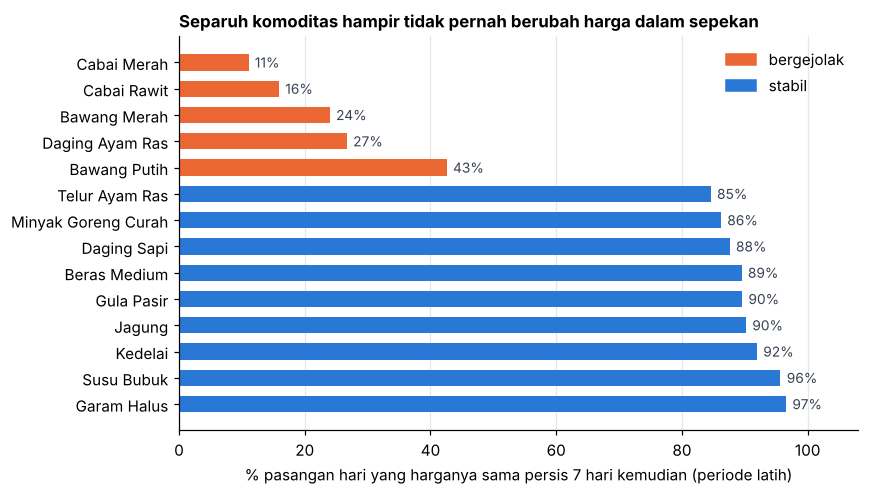

In [ ]:
GRUP = {"cabai_merah": "bergejolak", "cabai_rawit": "bergejolak", "bawang_merah": "bergejolak",
        "daging_ayam_ras": "bergejolak", "bawang_putih": "bergejolak"}
R["grup"] = R["komoditas"].map(GRUP).fillna("stabil")

s = sifat.iloc[::-1]
warna = [ORANYE if GRUP.get(k) else BIRU for k in sifat.index.map({v: k for k, v in NAMA.items()})][::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(s.index, s["persen_tidak_berubah"], color=warna, height=0.62)
for i, v in enumerate(s["persen_tidak_berubah"]):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=9, color="#374151")
ax.set_xlim(0, 108)
ax.set_xlabel("% pasangan hari yang harganya sama persis 7 hari kemudian (periode latih)")
ax.set_title("Separuh komoditas hampir tidak pernah berubah harga dalam sepekan", loc="left", fontsize=11, fontweight="bold")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ORANYE, label="bergejolak"), Patch(color=BIRU, label="stabil")], loc="upper right", frameon=False)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Arti untuk rumusan masalah:**

- Komoditas terbagi jelas menjadi dua kelompok. **Bergejolak** (cabai merah, cabai rawit, bawang merah, daging ayam ras, bawang putih)
  berubah hampir setiap minggu. **Stabil** (beras, gula, minyak goreng, daging sapi, telur, jagung, kedelai, garam, susu)
  berubah harga pada kurang dari 16% minggu.
- Pada komoditas stabil, tebakan "harga tetap" sudah benar di sekitar 85–97% kasus. Model sulit dan **tidak perlu** mengalahkannya jauh;
  yang penting tidak lebih buruk. Nilai tambah model ada pada komoditas bergejolak.
- Karena itu evaluasi dilaporkan **per kelompok** dan **per komoditas**, bukan hanya rata-rata gabungan.

### S1.5 Pembagian data (kronologis, tanpa kebocoran)

Baris dibagi menurut **hari asal t** dan **hari target t + h**. Sebuah baris baru boleh dipakai bila target-nya sudah terjadi
sebelum batas bagian, sehingga ada **jeda h hari** di setiap batas (baris di jeda tidak dipakai).

| Bagian | Syarat baris | Fungsi |
|---|---|---|
| Latih | t + h ≤ 31 Mar 2026 | Melatih model dan memilih fitur |
| Validasi | t ≥ 1 Apr 2026 dan t + h ≤ 30 Jun 2026 | Tuning hiperparameter dan memilih algoritma (S3) |
| Uji | t ≥ 1 Jul 2026 (sampai 15 Okt 2026) | **Hanya sekali**, untuk angka final (S4). Model final dilatih ulang dengan latih + validasi |

Metrik hanya dihitung pada baris yang hari asal dan hari target-nya **data asli**.

bagian,latih,validasi,uji,jeda
h = 7 hari,63772,7190,10979,1443
h = 14 hari,63052,6715,10149,2411


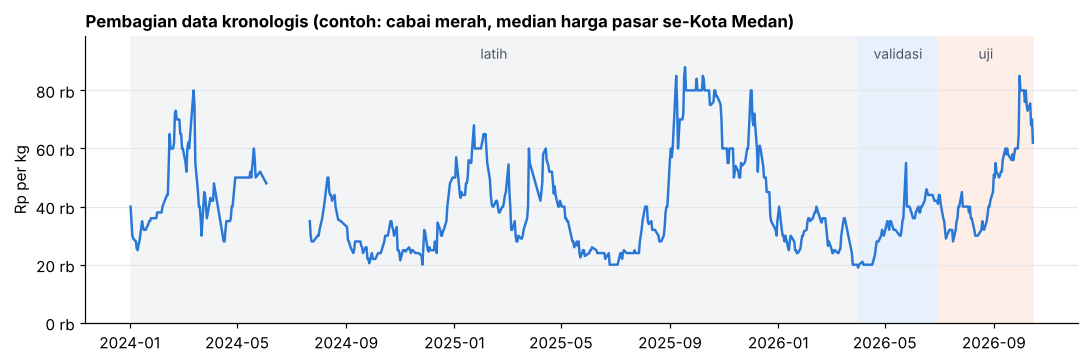

In [ ]:
tabel_bagian = R.groupby(["h", "bagian"]).size().unstack()[["latih", "validasi", "uji", "jeda"]]
tabel_bagian.index = [f"h = {h} hari" for h in tabel_bagian.index]
display(tabel_bagian)

# Contoh: harga cabai merah level kota dengan pembagian data
d = seri[("KOTA MEDAN", "SEMUA", "cabai_merah", "SIMPANG")][1]
asli = d[d["asli"]]
fig, ax = plt.subplots(figsize=(10, 3.4))
for (a, b, lab, c) in [(asli.index.min(), TRAIN_END, "latih", "#f3f4f6"), (VAL_START, VAL_END, "validasi", "#e8f0fb"),
                       (TEST_START, asli.index.max(), "uji", "#fdeee7")]:
    ax.axvspan(a, b, color=c, zorder=0)
    ax.text(a + (b - a) / 2, asli["harga"].max() * 1.02, lab, ha="center", va="bottom", fontsize=9, color="#4b5563")
# putus garis pada celah lebih dari 14 hari (tidak ada data, bukan harga datar)
garis = asli["harga"].copy()
celah = garis.index.to_series().diff().dt.days > 14
garis = pd.concat([garis, pd.Series(np.nan, index=garis.index[celah] - pd.Timedelta(days=1))]).sort_index()
ax.plot(garis.index, garis.values, color=BIRU, lw=1.6)
ax.set_ylim(0, asli["harga"].max() * 1.12)
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f} rb")
ax.set_ylabel("Rp per kg")
ax.set_title("Pembagian data kronologis (contoh: cabai merah, median harga pasar se-Kota Medan)", loc="left", fontsize=11, fontweight="bold")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Catatan: periode uji (Juli–Oktober 2026) **tidak memuat hari besar nasional**, sedangkan Iduladha 2026 ada di periode validasi.
Pengaruh fitur hari besar karena itu dinilai di data validasi dan lewat validasi silang deret waktu (S2–S3), bukan di data uji saja.
Periode uji juga memuat lonjakan cabai September–Oktober 2026, sehingga menjadi ujian yang berat bagi semua model.

### S1.6 Metrik dan baseline

**Metrik regresi** (dihitung pada skala rupiah setelah konversi):

| Metrik | Arti | Peran |
|---|---|---|
| **MAPE** | rata-rata meleset dalam persen harga | **metrik utama**, mudah dipahami pengguna; dipakai memilih model di data validasi |
| **MAE** | rata-rata meleset dalam rupiah | **syarat "berguna"**: model harus punya MAE lebih kecil dari baseline naif |
| RMSE | seperti MAE, tetapi menghukum kesalahan besar lebih berat | pelengkap (lonjakan) |
| R² perubahan | seberapa banyak variasi **perubahan** harga yang dijelaskan model | pelengkap; 0 = sama dengan menebak "tidak berubah" |

R² dihitung pada skala **perubahan**, bukan harga. Pada skala harga, tebakan "harga tetap" saja sudah mendapat R² sekitar 0,98
karena harga hari ini sangat mirip dengan harga minggu depan, sehingga angka itu menyesatkan (lihat kolom `R2_harga` di bawah).

**Baseline:**
1. **Naif ("harga tetap")**: $\hat y = 0$, harga hari ini dianggap berlaku h hari lagi. Ini patokan akal sehat yang harus dikalahkan.
2. **Model lama**: model yang sekarang berjalan di aplikasi (`GradientBoostingRegressor` satu per deret, hiperparameter tetap,
   kode `ml/app/fitur.py` dan `model.py` tanpa perubahan), dilatih ulang dengan data latih + validasi lalu diuji di data uji.
   Ini patokan **"sebelum"** untuk laporan.
3. **Linear Regression** sebagai baseline algoritma yang diminta panduan dikerjakan di S3 bersama dua algoritma lain.

In [ ]:
def metrik(harga_t, y, p):
    aktual, pred = harga_t * np.exp(y), harga_t * np.exp(p)
    e = pred - aktual
    ss_y = ((y - y.mean()) ** 2).sum()
    return {"n": len(y), "MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean()), "MAPE": (np.abs(e) / aktual).mean() * 100,
            "R2_perubahan": 1 - ((y - p) ** 2).sum() / ss_y if ss_y > 0 else np.nan,
            "R2_harga": 1 - (e ** 2).sum() / ((aktual - aktual.mean()) ** 2).sum()}

naif = (R[R.bagian.isin(["validasi", "uji"])].groupby(["bagian", "h"])
        .apply(lambda g: pd.Series(metrik(g.harga_t.values, g.y.values, np.zeros(len(g))))))
print("Baseline naif pada data validasi dan uji")
display(naif.round(3))

Baseline naif pada data validasi dan uji


n       MAE      RMSE   MAPE  R2_perubahan  R2_harga
bagian   h                                                             
uji      7   10979.0  1692.196  4266.927  3.713        -0.003     0.985
         14  10149.0  2361.957  5457.847  5.167        -0.012     0.975
validasi 7    7190.0  1298.665  2827.089  3.832        -0.011     0.993
         14   6715.0  1808.511  3622.675  5.276        -0.030     0.988

In [7]:
# Model lama: dilatih per deret dengan data latih + validasi (t + h <= 30 Jun 2026), memprediksi hari asal di periode uji.
pred_lama = []
for k, (tk, d) in seri.items():
    for h in HORIZON:
        x, y, asli = fitur_lama.bangun(d, h)
        lengkap = x.notna().all(axis=1)
        latih = lengkap & y.notna() & (x.index + pd.Timedelta(days=h) <= VAL_END)
        uji = lengkap & y.notna() & asli & (x.index >= TEST_START)
        if latih.sum() < 50 or uji.sum() == 0:
            continue
        m = model_lama.latih(x[latih], y[latih])
        pred_lama.append(pd.DataFrame({"kunci": [k] * int(uji.sum()), "t": x.index[uji], "h": h,
                                       "pred_lama": model_lama.prediksi_log(m, x[uji])}))
U = R[R.bagian == "uji"].merge(pd.concat(pred_lama), on=["kunci", "t", "h"], how="inner")
print(f"Baris uji dengan prediksi model lama: {len(U):,} dari {(R.bagian == 'uji').sum():,}")

baris = []
for (h, grup), gg in list(U.groupby(["h", "grup"])) + [((h, "semua"), gg) for h, gg in U.groupby("h")]:
    for nama, p in [("naif", np.zeros(len(gg))), ("model lama", gg.pred_lama.values)]:
        baris.append({"h": h, "kelompok": grup, "model": nama, **metrik(gg.harga_t.values, gg.y.values, p)})
patokan = pd.DataFrame(baris).set_index(["h", "kelompok", "model"])
display(patokan.round(3))

Baris uji dengan prediksi model lama: 21,013 dari 21,128


n       MAE      RMSE    MAPE  R2_perubahan  R2_harga
h  kelompok   model                                                                
7  bergejolak naif         4627  3567.411  5933.813   7.770        -0.010     0.826
              model lama   4627  4028.074  6256.883   8.901        -0.149     0.807
   stabil     naif         6292   329.341  2424.109   0.765        -0.001     0.997
              model lama   6292   575.686  2433.768   1.575        -0.349     0.997
14 bergejolak naif         4280  4903.076  7644.854  10.565        -0.036     0.719
              model lama   4280  5505.857  8107.937  12.047        -0.164     0.684
   stabil     naif         5814   513.645  2995.810   1.242        -0.001     0.995
              model lama   5814   803.130  2960.281   2.254        -0.303     0.995
7  semua      naif        10919  1701.495  4278.634   3.734        -0.003     0.985
              model lama  10919  2038.659  4472.438   4.679        -0.160     0.983
14 semua      naif        10094  2374.826  5472.696   5.195        -0.012     0.975
              model lama  10094  2797.153  5737.738   6.406        -0.154     0.973

In [8]:
per_kom = []
for kom, gg in U[U.h == 7].groupby("komoditas"):
    a = metrik(gg.harga_t.values, gg.y.values, np.zeros(len(gg)))
    b = metrik(gg.harga_t.values, gg.y.values, gg.pred_lama.values)
    per_kom.append({"komoditas": NAMA[kom], "kelompok": GRUP.get(kom, "stabil"), "n_uji": a["n"],
                    "MAPE naif": a["MAPE"], "MAPE model lama": b["MAPE"], "MAE naif": a["MAE"], "MAE model lama": b["MAE"],
                    "model lama lebih baik?": "ya" if b["MAE"] < a["MAE"] else "tidak"})
per_kom = pd.DataFrame(per_kom).sort_values("MAPE naif", ascending=False)
display(per_kom.round(2).set_index("komoditas"))

menang = []
for (k, h), gg in U.groupby(["kunci", "h"]):
    a = metrik(gg.harga_t.values, gg.y.values, np.zeros(len(gg)))["MAE"]
    b = metrik(gg.harga_t.values, gg.y.values, gg.pred_lama.values)["MAE"]
    menang.append({"h": h, "menang": b < a})
menang = pd.DataFrame(menang).groupby("h")["menang"].agg(["sum", "size"])
for h, r in menang.iterrows():
    print(f"h = {h}: model lama lebih baik dari naif pada {r['sum']} dari {r['size']} deret")

,kelompok,n_uji,MAPE naif,MAPE model lama,MAE naif,MAE model lama,model lama lebih baik?
komoditas,,,,,,,
Cabai Merah,bergejolak,929,14.28,15.14,6824.18,7149.07,tidak
Cabai Rawit,bergejolak,920,9.99,11.17,6111.23,6866.72,tidak
Bawang Merah,bergejolak,938,5.59,7.14,1622.68,2086.34,tidak
Daging Ayam Ras,bergejolak,915,4.76,5.74,1910.56,2343.79,tidak
Bawang Putih,bergejolak,925,4.21,5.29,1377.48,1705.38,tidak
Garam Halus,stabil,68,1.65,1.65,137.26,137.26,tidak
Jagung,stabil,827,1.38,2.80,129.18,249.88,tidak
Daging Sapi,stabil,934,1.27,1.78,1532.39,2253.81,tidak
Telur Ayam Ras,stabil,937,1.24,3.30,330.98,873.96,tidak


h = 7: model lama lebih baik dari naif pada 11 dari 165 deret
h = 14: model lama lebih baik dari naif pada 19 dari 165 deret


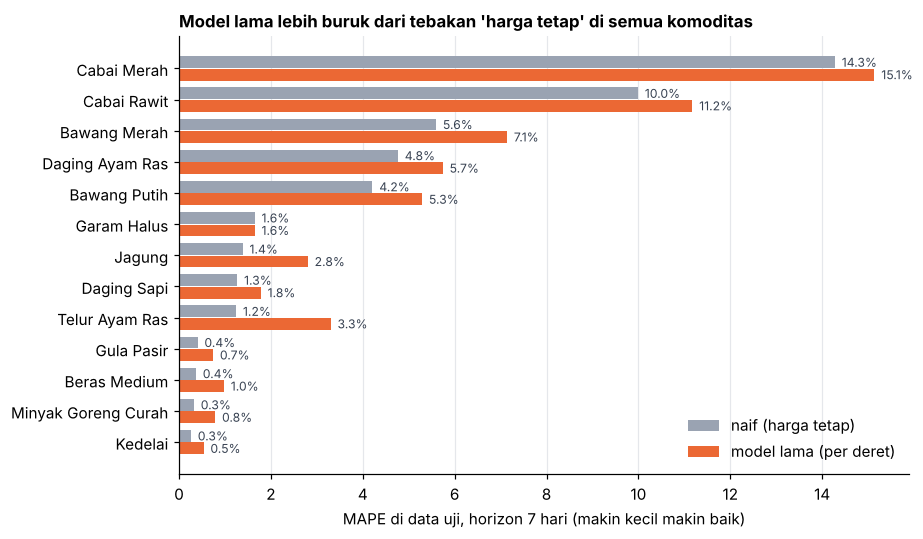

In [9]:
p = per_kom.iloc[::-1]
yy = np.arange(len(p))
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(yy + 0.2, p["MAPE naif"], height=0.38, color=ABU, label="naif (harga tetap)")
ax.barh(yy - 0.2, p["MAPE model lama"], height=0.38, color=ORANYE, label="model lama (per deret)")
for i, (a, b) in enumerate(zip(p["MAPE naif"], p["MAPE model lama"])):
    ax.text(a + 0.15, i + 0.2, f"{a:.1f}%", va="center", fontsize=8, color="#374151")
    ax.text(b + 0.15, i - 0.2, f"{b:.1f}%", va="center", fontsize=8, color="#374151")
ax.set_yticks(yy, p["komoditas"])
ax.set_xlabel("MAPE di data uji, horizon 7 hari (makin kecil makin baik)")
ax.set_title("Model lama lebih buruk dari tebakan 'harga tetap' di semua komoditas", loc="left", fontsize=11, fontweight="bold")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### S1.7 Status Normal / Waspada / Lonjakan

Status adalah keluaran turunan untuk pedagang dan pemerintah. Definisi yang disepakati (**kombinasi**):

- Ambang per komoditas dihitung dari sebaran perubahan harga 7 hari **pada periode latih saja**
  (sebelumnya dihitung dari seluruh data, yang membocorkan informasi data uji ke evaluasi status):
  **Waspada** = persentil 80 (minimal 2%), **Lonjakan** = persentil 95. Hanya kenaikan yang berstatus.
- Status deret = yang **paling tinggi** dari (a) kelas perubahan **aktual** 7 hari terakhir dan (b) kelas perubahan 7 hari yang
  **diprediksi** model. Alasannya ikut ditampilkan ("sudah naik x% sepekan terakhir" atau "diprediksi naik x%").
- Evaluasi: kelas "berisiko" (Waspada + Lonjakan) dibandingkan dengan kelas perubahan aktual 7 hari ke depan; metrik **recall**,
  **presisi**, dan **F1**. Recall diutamakan, karena kenaikan yang tidak terdeteksi lebih merugikan daripada peringatan berlebih.
- Patokan: **persistensi** (hanya bagian a) dan model lama (hanya bagian b).

In [10]:
maju, lalu = [], []
X = []
for k, (tk, d) in seri.items():
    p, a = d["harga"], d["asli"]
    X.append(pd.DataFrame({"kunci": [k] * len(p), "komoditas": k[2], "t": d.index,
                           "maju": ((p.shift(-7) / p - 1) * 100).where(a & a.shift(-7, fill_value=False)),
                           "lalu": ((p / p.shift(7) - 1) * 100).where(a & a.shift(7, fill_value=False))}))
X = pd.concat(X, ignore_index=True)

latih7 = X[(X.t + pd.Timedelta(days=7) <= TRAIN_END) & X.maju.notna()]
AMBANG = {}
for kom, gg in latih7.groupby("komoditas"):
    w = max(np.percentile(gg.maju, 80), 2.0)
    l = np.percentile(gg.maju, 95)
    AMBANG[kom] = (w, l if l > w else w * 1.5)
tabel_ambang = pd.DataFrame(AMBANG, index=["Waspada ≥ (%)", "Lonjakan ≥ (%)"]).T.sort_values("Waspada ≥ (%)")
tabel_ambang.index = tabel_ambang.index.map(NAMA)
display(tabel_ambang.round(1))

Us = X[(X.t >= TEST_START) & X.maju.notna()].merge(
    U[U.h == 7][["kunci", "t", "pred_lama"]], on=["kunci", "t"], how="left")
Us["pred_pct"] = (np.exp(Us.pred_lama) - 1) * 100
berisiko = lambda v, kom: np.array([pd.notna(x) and x >= AMBANG[k][0] for x, k in zip(v, kom)])
aktual = berisiko(Us.maju, Us.komoditas)
hasil = []
for nama, pr in [("persistensi (aktual 7 hari terakhir)", berisiko(Us.lalu, Us.komoditas)),
                 ("model lama (prediksi saja)", berisiko(Us.pred_pct, Us.komoditas)),
                 ("kombinasi: aktual ATAU model lama", berisiko(Us.lalu, Us.komoditas) | berisiko(Us.pred_pct, Us.komoditas))]:
    tp, fp, fn = (pr & aktual).sum(), (pr & ~aktual).sum(), (~pr & aktual).sum()
    hasil.append({"aturan": nama, "hari uji": len(aktual), "kejadian berisiko": int(aktual.sum()), "ditandai": int(pr.sum()),
                  "recall": tp / (tp + fn), "presisi": tp / (tp + fp) if tp + fp else np.nan, "F1": 2 * tp / (2 * tp + fp + fn)})
display(pd.DataFrame(hasil).set_index("aturan").round(3))

,Waspada ≥ (%),Lonjakan ≥ (%)
Beras Medium,2.0,3.0
Garam Halus,2.0,3.0
Daging Sapi,2.0,3.0
Susu Bubuk,2.0,3.0
Minyak Goreng Curah,2.0,3.1
Kedelai,2.0,3.0
Jagung,2.0,6.2
Gula Pasir,2.0,3.0
Telur Ayam Ras,2.0,2.8
Bawang Putih,2.9,10.0


,hari uji,kejadian berisiko,ditandai,recall,presisi,F1
aturan,,,,,,
persistensi (aktual 7 hari terakhir),10979,1231,1185,0.202,0.210,0.206
model lama (prediksi saja),10979,1231,1041,0.166,0.196,0.180
kombinasi: aktual ATAU model lama,10979,1231,2188,0.365,0.205,0.263


### S1.8 Ringkasan S1: keputusan dan kriteria sukses

**Rumusan:** regresi perubahan harga log 7 dan 14 hari ke depan, 169 deret (12 level kota, 157 level kecamatan), satu model gabungan
per horizon; status sebagai turunan dengan aturan kombinasi.

**Patokan "sebelum" (data uji, horizon 7 hari):** baseline naif MAPE ≈ 3,7%; model lama MAPE ≈ 4,7% dan lebih baik dari naif
hanya pada 11 dari 165 deret. Status: persistensi recall ≈ 0,20; kombinasi dengan model lama recall ≈ 0,36 pada presisi ≈ 0,20.

**Kriteria sukses** (dinilai di data uji pada S4, angka pastinya dicetak di sel di atas):

| Kelompok | Minimum | Target |
|---|---|---|
| Bergejolak (5 komoditas), h = 7 dan 14 | MAE model **lebih kecil** dari naif | MAE ≥ 5% lebih kecil dari naif |
| Stabil (9 komoditas), h = 7 dan 14 | MAE model **tidak lebih dari 5% lebih buruk** dari naif | sama atau lebih baik dari naif |
| Semua deret | lebih baik dari model lama | |
| Status (kelas berisiko) | recall **dan** F1 lebih tinggi dari persistensi | recall ≥ 0,40 dengan presisi tidak turun |

Bila kriteria minimum tidak tercapai pada suatu kelompok, hal itu dilaporkan apa adanya sebagai temuan, dan aplikasi memakai
baseline naif untuk kelompok itu (dijelaskan di S5).

## S2. Preprocessing dan feature engineering

Tujuan S2: menyiapkan data dan fitur untuk **satu model gabungan per horizon** (keputusan S1), lalu **membuktikan** fitur mana
yang benar-benar menurunkan galat. Kode fitur tidak ditulis di notebook, melainkan di `ml/app/fitur_global.py`, supaya
aplikasi (S6) memakai fungsi yang sama persis dengan eksperimen ini. Tesnya ada di `ml/tests/test_fitur_global.py`.

| Bagian | Isi |
|---|---|
| S2.1 | Alur preprocessing dan cek konsistensi dengan S1 |
| S2.2 | Fitur kandidat: rumus dan alasan |
| S2.3 | Cek kebocoran data pada data asli |
| S2.4 | Ablation: kelompok fitur mana yang menurunkan galat (validasi silang 4 lipatan waktu) |
| S2.5 | Fitur yang paling berpengaruh (permutation importance) |
| S2.6 | Ringkasan dan keputusan untuk S3 |

Semua angka S2 hanya memakai data **latih dan validasi** (hari target sampai 30 Juni 2026). Data uji tetap belum disentuh.

### S2.1 Alur preprocessing

| Langkah | Perlakuan | Alasan |
|---|---|---|
| 1. Potret data | Data bersih sampai **15 Oktober 2026** (`BATAS_DATA`) | Angka laporan dapat direproduksi walau scraper terus menambah data (keputusan S1) |
| 2. Agregasi harian | Kecamatan = rata-rata pasar; Kota Medan = median pasar (minimal 3 pasar). Ikut dicatat: jumlah pasar melapor dan sebaran harga antarpasar (koefisien variasi) | Sama dengan view `harga_agregat` di aplikasi |
| 3. Deret harian | Indeks kalender harian; hari tanpa data diisi interpolasi linear **paling lama 14 hari**, hanya untuk mengisi jendela bergulir | Akhir pekan dan libur tidak punya data; jendela 7 atau 28 hari tetap bermakna |
| 4. Baris model | Hanya hari asal *t* yang data asli, dan (untuk latih/evaluasi) hari target *t + h* juga data asli | Model tidak belajar dari, dan tidak dinilai dengan, harga hasil interpolasi |
| 5. Target | $y = \ln P_{t+h} - \ln P_t$ | Skala sama untuk semua komoditas (S1) |
| 6. Nilai kosong | Dibiarkan `NaN` (mis. sebaran antarpasar bila hanya 1 pasar); model pohon menanganinya langsung. Untuk model linear di S3: imputasi median **dari data latih** + standardisasi **dari data latih** | Statistik pengisi tidak boleh dihitung dari data validasi/uji |
| 7. Kategori | Komoditas sebagai kode kategori (model pohon) atau one-hot (model linear di S3) | |

In [11]:
from app import fitur_global as fg

agregat_v2 = fg.agregat_harian(raw)
seri_v2, _ = fg.bangun_deret(agregat_v2, min_hari=MIN_HARI, celah=CELAH_MAKS)
KODE = fg.kode_komoditas([k["kode"] for k in REF["komoditas"]])

def bagian_dari(t, h):
    tt = t + pd.Timedelta(days=h)
    return np.select([tt <= TRAIN_END, (t >= VAL_START) & (tt <= VAL_END), t >= TEST_START],
                     ["latih", "validasi", "uji"], default="jeda")

TAB = {}
for h in HORIZON:
    T = fg.tabel_fitur(seri_v2, h, KODE)
    T["bagian"] = bagian_dari(T["t"], h)
    T["grup"] = np.where(T["bergejolak"] == 1, "bergejolak", "stabil")
    TAB[h] = T

# Konsistensi dengan S1: baris, harga, dan target harus sama persis dengan tabel R di S1.3
for h in HORIZON:
    a = TAB[h][["kunci", "t", "harga_t", "y"]].sort_values(["kunci", "t"]).reset_index(drop=True)
    b = R[R.h == h][["kunci", "t", "harga_t", "y"]].sort_values(["kunci", "t"]).reset_index(drop=True)
    assert len(a) == len(b) and (a.kunci == b.kunci).all() and (a.t == b.t).all()
    assert np.allclose(a.harga_t, b.harga_t) and np.allclose(a.y, b.y)
print(f"Deret: {len(seri_v2)}  ·  baris h=7: {len(TAB[7]):,}  ·  baris h=14: {len(TAB[14]):,}  ·  sama persis dengan S1: ya")
display(pd.DataFrame({h: TAB[h].bagian.value_counts() for h in HORIZON}).T[["latih", "validasi", "uji", "jeda"]]
        .rename(index=lambda h: f"h = {h} hari"))

Deret: 169  ·  baris h=7: 83,384  ·  baris h=14: 82,327  ·  sama persis dengan S1: ya


bagian,latih,validasi,uji,jeda
h = 7 hari,63772,7190,10979,1443
h = 14 hari,63052,6715,10149,2411


### S2.2 Fitur kandidat

Semua fitur dihitung per deret pada hari asal *t*, dengan $\ell_t = \ln P_t$. Fitur kalender memakai tanggal target *t + h*,
yang sudah diketahui sebelumnya.

| Kelompok | Fitur | Rumus | Alasan |
|---|---|---|---|
| **Identitas** | `komoditas_kode`, `bergejolak`, `tingkat_kota` | kode komoditas; 1 bila komoditas bergejolak; 1 bila deret Kota Medan | Satu model untuk 14 komoditas perlu tahu deret mana yang sedang diprediksi |
| **Momentum** | `ret_1`, `ret_3`, `ret_7`, `ret_14`, `ret_28` | $\ell_t - \ell_{t-k}$ | Arah dan kecepatan gerak harga terakhir |
| | `rasio_ma30`, `rasio_ma90`, `rasio_ma365` | $\ell_t - \ln \overline{P}_{\text{30/90/365 hari}}$ | Seberapa jauh harga dari rata-ratanya; harga yang melonjak cenderung kembali |
| **Volatilitas** | `vol14`, `vol56` | simpangan baku $\Delta\ell$ harian dalam 14 dan 56 hari | Deret yang sedang bergejolak lebih mungkin berubah lagi |
| | `frac_berubah_28` | porsi hari data asli dalam 28 hari terakhir yang harganya berubah dari hari data sebelumnya | Mengukur "kelengketan" harga (S1.4) secara langsung |
| | `hari_sejak_berubah` | hari sejak harga terakhir berubah (maks. 120) | Harga yang lama diam cenderung tetap diam |
| **Pasar dan wilayah** | `n_pasar` | jumlah pasar yang melapor hari *t* | Harga dari 1 pasar lebih berisik daripada median 21 pasar |
| | `dispersi` | koefisien variasi harga antarpasar hari *t* | Sebaran lebar menandakan pasar belum seragam, harga cenderung menyesuaikan |
| | `selisih_kota` | $\ell^{\text{kec}}_t - \ell^{\text{kota}}_t$ (0 untuk deret kota) | Harga kecamatan yang jauh di atas/bawah kota cenderung kembali ke harga kota |
| | `ret_7_kota` | perubahan 7 hari harga Kota Medan komoditas yang sama | Gerak harga kota mendahului kecamatan |
| **Kalender** | `hb_menjelang`, `hb_target`, `hari_ke_hb` | ada hari besar dalam 14 hari; target ±3 hari dari hari besar; hari ke hari besar berikutnya | Permintaan naik menjelang hari besar |
| | `ramadan_target` | target berada di Ramadan sampai Idulfitri (mulai 7 hari sebelumnya) | Musim permintaan tinggi |
| | `bulan_sin`, `bulan_cos` | bulan target dalam bentuk siklus | Pola musiman (panen) |

Kelompok **pasar dan wilayah** baru dimungkinkan oleh model gabungan: model per deret yang lama tidak bisa melihat harga kota
atau pasar lain.

In [12]:
L7 = TAB[7][TAB[7].bagian == "latih"]
ringkas_fitur = pd.DataFrame({
    "kelompok": [g for g, fs in fg.FITUR_GRUP.items() for _ in fs],
    "kosong (%)": [L7[f].isna().mean() * 100 for f in fg.SEMUA_FITUR],
    "median": [L7[f].median() for f in fg.SEMUA_FITUR],
    "p5": [L7[f].quantile(0.05) for f in fg.SEMUA_FITUR],
    "p95": [L7[f].quantile(0.95) for f in fg.SEMUA_FITUR],
}, index=fg.SEMUA_FITUR)
print("Ringkasan fitur pada data latih (h = 7)")
display(ringkas_fitur.round(3))

Ringkasan fitur pada data latih (h = 7)


,kelompok,kosong (%),median,p5,p95
komoditas_kode,identitas,0.000,5.000,0.000,13.000
bergejolak,identitas,0.000,0.000,0.000,1.000
tingkat_kota,identitas,0.000,0.000,0.000,1.000
ret_1,momentum,0.246,0.000,-0.063,0.054
ret_3,momentum,0.750,0.000,-0.105,0.095
ret_7,momentum,1.403,0.000,-0.145,0.134
ret_14,momentum,2.617,0.000,-0.210,0.182
ret_28,momentum,6.169,0.000,-0.288,0.288
rasio_ma30,momentum,4.157,0.000,-0.180,0.150
rasio_ma90,momentum,6.420,0.000,-0.293,0.271


Nilai kosong terbesar ada di `dispersi` (kecamatan dengan satu pasar, sebaran tidak terdefinisi) dan `rasio_ma365`
(butuh minimal 180 hari riwayat). Keduanya dibiarkan kosong, bukan diisi 0, karena "tidak terdefinisi" berbeda dengan "nol".

### S2.3 Cek kebocoran data

Fitur pada hari *t* harus **sama persis** bila semua data sesudah *t* dihapus. Cek di bawah memotong deret (dan deret kota
komoditas yang sama) tepat di hari *t*, menghitung ulang fiturnya, lalu membandingkan dengan fitur dari data lengkap.
Tes otomatis yang sama ada di `ml/tests/test_fitur_global.py`.

In [13]:
rng = np.random.default_rng(SEED)
selisih_maks, dicek = 0.0, 0
for h in HORIZON:
    penuh = TAB[h]
    for i in rng.choice(len(penuh), 40, replace=False):
        r = penuh.iloc[i]
        kunci_kota = (fg.KOTA, "SEMUA", r.kunci[2], r.kunci[3])
        potong = {k: seri_v2[k].loc[: r.t] for k in {r.kunci, kunci_kota} if k in seri_v2}
        s = fg.tabel_fitur(potong, h, KODE, hanya_target_asli=False)
        s = s[(s.kunci == r.kunci) & (s.t == r.t)].iloc[0]
        a = pd.to_numeric(r[fg.SEMUA_FITUR]).astype(float).values
        b = pd.to_numeric(s[fg.SEMUA_FITUR]).astype(float).values
        sama = np.isclose(a, b, rtol=1e-12, atol=1e-12) | (np.isnan(a) & np.isnan(b))
        assert sama.all(), (r.kunci, r.t, np.array(fg.SEMUA_FITUR)[~sama])
        selisih_maks = max(selisih_maks, np.nanmax(np.abs(a - b)))
        dicek += 1
print(f"{dicek} baris acak dicek: fitur sama persis setelah data sesudah t dihapus (selisih maks {selisih_maks:.1e}). Tidak ada kebocoran.")

80 baris acak dicek: fitur sama persis setelah data sesudah t dihapus (selisih maks 0.0e+00). Tidak ada kebocoran.


### S2.4 Ablation: kelompok fitur mana yang benar-benar membantu?

**Rancangan.**
- **Model penguji tetap:** `HistGradientBoostingRegressor` (scikit-learn) dengan hiperparameter tetap dan `loss="absolute_error"`.
  Loss absolut dipilih karena kriteria sukses memakai MAE dan targetnya sering bernilai nol (harga lengket); perbandingannya
  dengan loss kuadrat ada di sel berikutnya. Pemilihan algoritma dan tuning adalah tugas S3, bukan S2.
- **Validasi silang 4 lipatan waktu (expanding window).** Setiap lipatan melatih model dengan semua baris yang hari targetnya
  sebelum awal lipatan, lalu menilai di lipatan itu:

  | Lipatan | Periode hari asal dan target | Catatan |
  |---|---|---|
  | 1 | Jul–Sep 2025 | |
  | 2 | Okt–Des 2025 | |
  | 3 | Jan–Mar 2026 | memuat Ramadan dan Idulfitri 2026 |
  | 4 | Apr–Jun 2026 | sama dengan data validasi S1; memuat Iduladha 2026 |

  Satu periode validasi saja (3 bulan) terlalu berisik untuk memutuskan fitur, jadi keputusan diambil dari rata-rata 4 lipatan
  **dan** berapa lipatan yang konsisten membaik.
- **Ukuran:** selisih MAE (rupiah) terhadap baseline naif, dalam persen, per kelompok komoditas. Negatif berarti lebih baik dari naif.
- **Urutan uji:** fitur ditambah per kelompok (identitas + momentum, lalu volatilitas, lalu pasar dan wilayah = set **B**),
  lalu tiap kelompok dikeluarkan dari B satu per satu, lalu tiap bagian kalender ditambahkan ke B.

In [14]:
from sklearn.ensemble import HistGradientBoostingRegressor

LIPATAN = [("2025-07-01", "2025-09-30"), ("2025-10-01", "2025-12-31"), ("2026-01-01", "2026-03-31"), ("2026-04-01", "2026-06-30")]
PARAM_PENGUJI = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50, l2_regularization=1.0,
                     early_stopping=False, random_state=SEED)

def mae_rp(g, p):
    return np.abs(g.harga_t.values * (np.exp(p) - np.exp(g.y.values))).mean()

def penguji(cols, loss="absolute_error"):
    return HistGradientBoostingRegressor(loss=loss, categorical_features=[c in fg.KATEGORI for c in cols], **PARAM_PENGUJI)

def uji_lipatan(cols, loss="absolute_error"):
    hasil = []
    for h in HORIZON:
        T = TAB[h]
        tt = T.t + pd.Timedelta(days=h)
        for i, (a, b) in enumerate(LIPATAN, 1):
            a, b = pd.Timestamp(a), pd.Timestamp(b)
            L, V = T[tt < a], T[(T.t >= a) & (tt <= b)]
            m = penguji(cols, loss).fit(L[cols], L.y)
            p = m.predict(V[cols])
            for grup in ("bergejolak", "stabil"):
                s = (V.grup == grup).values
                naif_ = mae_rp(V[s], np.zeros(s.sum()))
                hasil.append({"h": h, "lipatan": i, "kelompok": grup, "MAE": mae_rp(V[s], p[s]), "MAE naif": naif_})
    out = pd.DataFrame(hasil)
    out["vs naif (%)"] = (out["MAE"] / out["MAE naif"] - 1) * 100
    return out

G = fg.FITUR_GRUP
B = G["identitas"] + G["momentum"] + G["volatilitas"] + G["pasar_wilayah"]
KONFIG = [
    ("identitas + momentum", G["identitas"] + G["momentum"]),
    ("+ volatilitas", G["identitas"] + G["momentum"] + G["volatilitas"]),
    ("+ pasar dan wilayah = B", B),
    ("B tanpa momentum", [c for c in B if c not in G["momentum"]]),
    ("B tanpa volatilitas", [c for c in B if c not in G["volatilitas"]]),
    ("B tanpa pasar dan wilayah", [c for c in B if c not in G["pasar_wilayah"]]),
    ("B + hari besar", B + ["hb_menjelang", "hb_target", "hari_ke_hb"]),
    ("B + Ramadan", B + ["ramadan_target"]),
    ("B + bulan", B + ["bulan_sin", "bulan_cos"]),
]
ABL = pd.concat([uji_lipatan(cols).assign(konfigurasi=nama) for nama, cols in KONFIG], ignore_index=True)

URUT = [n for n, _ in KONFIG]
ringkas_abl = (ABL.groupby(["h", "kelompok", "konfigurasi"])["vs naif (%)"]
               .agg(rata="mean", terbaik="min", terburuk="max", lipatan_lebih_baik_dari_naif=lambda v: int((v < 0).sum()))
               .reset_index())
ringkas_abl["konfigurasi"] = pd.Categorical(ringkas_abl["konfigurasi"], URUT, ordered=True)
tabel_abl = ringkas_abl.sort_values(["h", "kelompok", "konfigurasi"]).set_index(["h", "kelompok", "konfigurasi"])
display(tabel_abl.round(1))

rata  terbaik  terburuk  lipatan_lebih_baik_dari_naif
h  kelompok   konfigurasi                                                                     
7  bergejolak identitas + momentum        4.7     -5.1      22.3                             2
              + volatilitas               3.9     -4.9      21.1                             2
              + pasar dan wilayah = B    -1.3    -10.8      13.5                             3
              B tanpa momentum           -3.3     -4.9      -1.7                             4
              B tanpa volatilitas         0.1    -10.7      17.2                             3
              B tanpa pasar dan wilayah   3.9     -4.9      21.1                             2
              B + hari besar              2.3     -9.8      19.7                             2
              B + Ramadan                 0.1     -7.4      16.0                             3
              B + bulan                   2.6     -7.2      22.1                             3
   stabil     identitas + momentum        2.6      1.1       4.7                             0
              + volatilitas               0.2     -1.7       2.3                             2
              + pasar dan wilayah = B     0.1     -1.5       2.3                             2
              B tanpa momentum            0.7      0.0       1.4                             0
              B tanpa volatilitas         1.9      0.7       3.3                             0
              B tanpa pasar dan wilayah   0.2     -1.7       2.3                             2
              B + hari besar              0.4     -1.9       2.0                             1
              B + Ramadan                 0.4     -1.4       2.1                             1
              B + bulan                  -0.1     -2.1       2.2                             2
14 bergejolak identitas + momentum        2.1    -13.9      18.0                             2
              + volatilitas               0.8    -12.6      16.6                             2
              + pasar dan wilayah = B    -4.7    -18.8      10.1                             3
              B tanpa momentum           -1.3     -8.0       2.1                             2
              B tanpa volatilitas        -3.4    -18.5      11.0                             2
              B tanpa pasar dan wilayah   0.8    -12.6      16.6                             2
              B + hari besar              1.5    -14.9      24.1                             2
              B + Ramadan                -4.0    -16.5      11.1                             3
              B + bulan                   1.5     -6.8      22.9                             3
   stabil     identitas + momentum       12.6     -3.6      47.8                             1
              + volatilitas               2.9     -3.5       8.3                             1
              + pasar dan wilayah = B     6.7     -2.2      20.7                             1
              B tanpa momentum            0.4     -0.2       1.4                             1
              B tanpa volatilitas         3.3     -2.6       9.5                             2
              B tanpa pasar dan wilayah   2.9     -3.5       8.3                             1
              B + hari besar             13.5     -1.9      45.4                             1
              B + Ramadan                10.7     -2.9      35.1                             1
              B + bulan                  13.2     -2.3      35.0                             1

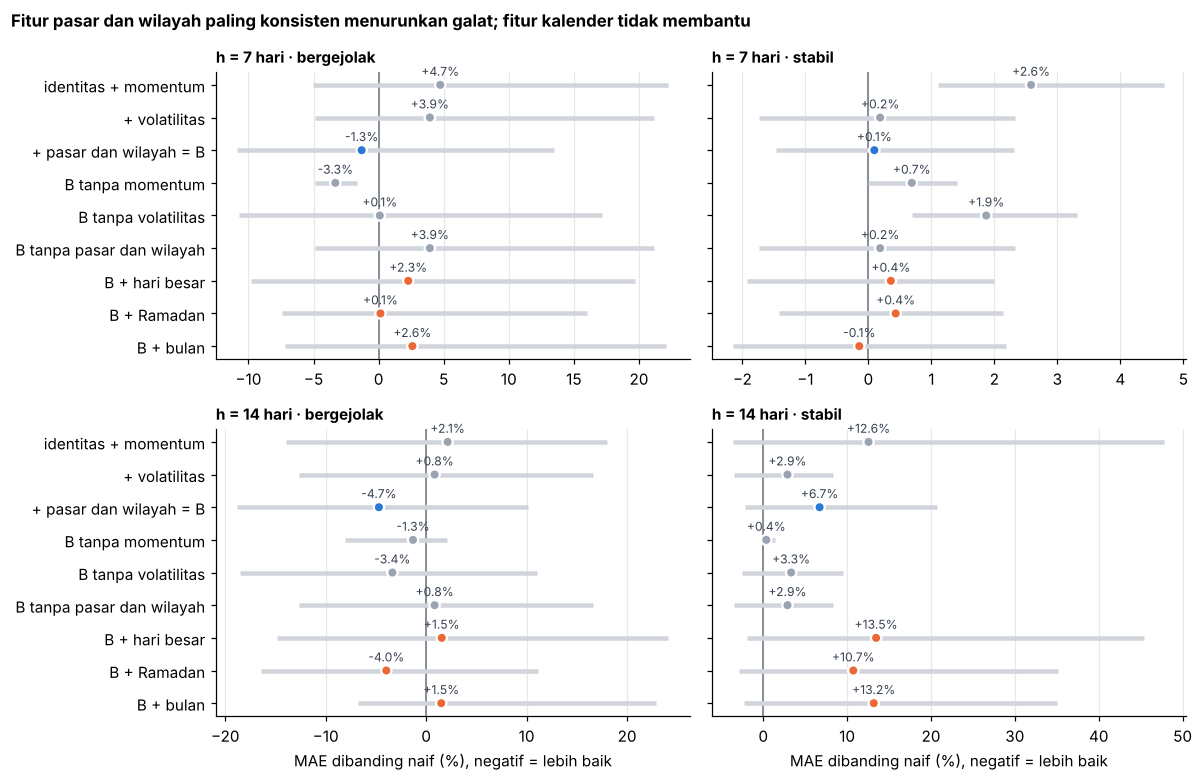

In [15]:
# Ringkasan visual: rata-rata selisih MAE terhadap naif (titik) dan rentang 4 lipatan (garis)
WARNA_KONF = {n: (BIRU if n == "+ pasar dan wilayah = B" else ORANYE if n.startswith("B +") else ABU) for n in URUT}
fig, axes = plt.subplots(2, 2, figsize=(11, 7.2), sharey=True)
for (h, grup), ax in zip([(7, "bergejolak"), (7, "stabil"), (14, "bergejolak"), (14, "stabil")], axes.flat):
    t = tabel_abl.loc[(h, grup)].reindex(URUT)
    yy = np.arange(len(URUT))[::-1]
    ax.axvline(0, color="#6b7280", lw=1)
    ax.hlines(yy, t["terbaik"], t["terburuk"], color="#d1d5db", lw=3)
    ax.scatter(t["rata"], yy, color=[WARNA_KONF[n] for n in URUT], s=46, zorder=3, edgecolor="white", linewidth=1.5)
    for y, v in zip(yy, t["rata"]):
        ax.text(v, y + 0.28, f"{v:+.1f}%", ha="center", fontsize=8, color="#374151")
    ax.set_yticks(yy, URUT)
    ax.set_title(f"h = {h} hari · {grup}", loc="left", fontsize=10, fontweight="bold")
    ax.grid(axis="y", visible=False)
for ax in axes[1]:
    ax.set_xlabel("MAE dibanding naif (%), negatif = lebih baik")
fig.suptitle("Fitur pasar dan wilayah paling konsisten menurunkan galat; fitur kalender tidak membantu",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

In [16]:
# Pembanding loss model penguji pada set B (alasan memakai loss absolut)
banding_loss = pd.concat([uji_lipatan(B, loss).assign(loss=loss) for loss in ("squared_error", "absolute_error")])
display(banding_loss.groupby(["h", "kelompok", "loss"])["vs naif (%)"].mean().unstack().round(1))

loss           absolute_error  squared_error
h  kelompok                                 
7  bergejolak            -1.3            8.8
   stabil                 0.1           51.5
14 bergejolak            -4.7            4.9
   stabil                 6.7           49.3

### S2.5 Fitur yang paling berpengaruh

Permutation importance pada lipatan 4 (April–Juni 2026) dengan set B: satu fitur diacak, lalu dicatat berapa rupiah MAE naik.
Makin besar kenaikannya, makin model bergantung pada fitur itu.

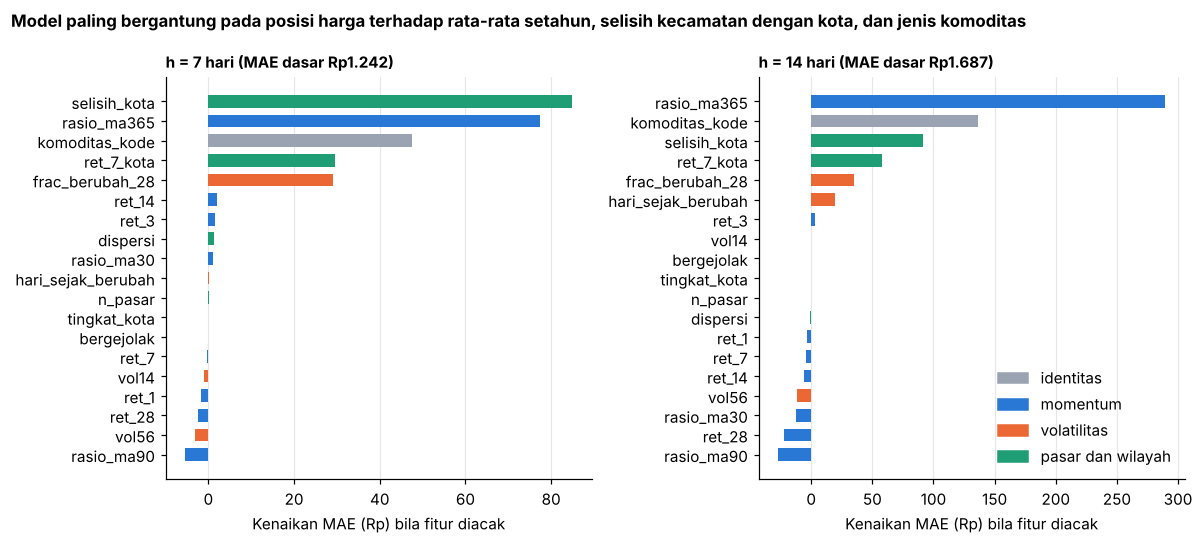

,h = 7 (Rp),h = 14 (Rp)
bergejolak,0.0,0.0
dispersi,1.3,-0.6
frac_berubah_28,29.0,35.0
hari_sejak_berubah,0.1,19.7
komoditas_kode,47.6,136.0
n_pasar,0.0,-0.0
rasio_ma30,1.0,-12.7
rasio_ma365,77.5,289.7
rasio_ma90,-5.4,-27.2
ret_1,-1.7,-3.1


In [17]:
def kepentingan(h, cols, ulang=5):
    T = TAB[h]
    tt = T.t + pd.Timedelta(days=h)
    a, b = pd.Timestamp(LIPATAN[-1][0]), pd.Timestamp(LIPATAN[-1][1])
    L, V = T[tt < a], T[(T.t >= a) & (tt <= b)]
    m = penguji(cols).fit(L[cols], L.y)
    dasar = mae_rp(V, m.predict(V[cols]))
    rng = np.random.default_rng(SEED)
    hasil = {}
    for c in cols:
        naik = []
        for _ in range(ulang):
            Vc = V[cols].copy()
            Vc[c] = rng.permutation(Vc[c].values)
            naik.append(mae_rp(V, m.predict(Vc)) - dasar)
        hasil[c] = np.mean(naik)
    return pd.Series(hasil).sort_values(ascending=False), dasar

KELOMPOK_FITUR = {f: g for g, fs in fg.FITUR_GRUP.items() for f in fs}
WARNA_GRUP = {"identitas": ABU, "momentum": BIRU, "volatilitas": ORANYE, "pasar_wilayah": "#1f9d74"}
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
PENTING = {}
for h, ax in zip(HORIZON, axes):
    s, dasar = kepentingan(h, B)
    PENTING[h] = s
    s = s.iloc[::-1]
    ax.barh(s.index, s.values, color=[WARNA_GRUP[KELOMPOK_FITUR[f]] for f in s.index], height=0.65)
    ax.set_title(f"h = {h} hari (MAE dasar Rp{dasar:,.0f})".replace(",", "."), loc="left", fontsize=10, fontweight="bold")
    ax.set_xlabel("Kenaikan MAE (Rp) bila fitur diacak")
    ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color=c, label=g.replace("_", " dan ")) for g, c in WARNA_GRUP.items()], frameon=False, loc="lower right")
fig.suptitle("Model paling bergantung pada posisi harga terhadap rata-rata setahun, selisih kecamatan dengan kota, dan jenis komoditas",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()
display(pd.DataFrame({f"h = {h} (Rp)": PENTING[h] for h in HORIZON}).round(1))

Beberapa fitur momentum (`ret_1`, `ret_7`, `ret_28`, `rasio_ma90`) dan volatilitas (`vol14`, `vol56`) bernilai **nol atau negatif**:
mengacaknya tidak menaikkan, bahkan menurunkan galat, artinya model memakainya untuk mempelajari gerak acak. Karena itu disusun set ringkas **K**: identitas,
`ret_3`, `ret_14`, `rasio_ma30`, `rasio_ma365`, `frac_berubah_28`, `hari_sejak_berubah`, dan seluruh kelompok pasar dan wilayah.

Set K dipilih dari kepentingan di lipatan 4, jadi pembuktiannya harus memakai **lipatan 1–3 yang tidak ikut dipakai memilih**.

In [18]:
K = fg.FITUR_TERPILIH
banding_k = pd.concat([uji_lipatan(B).assign(set_fitur="B (19 fitur)"), uji_lipatan(K).assign(set_fitur=f"K ({len(K)} fitur)")])
per_lipatan = banding_k.pivot_table(index=["h", "kelompok", "set_fitur"], columns="lipatan", values="vs naif (%)")
per_lipatan.columns = [f"lipatan {c}" for c in per_lipatan.columns]
per_lipatan["rata 1–3 (tidak dipakai memilih)"] = per_lipatan[["lipatan 1", "lipatan 2", "lipatan 3"]].mean(axis=1)
per_lipatan["rata 1–4"] = per_lipatan[[f"lipatan {i}" for i in range(1, 5)]].mean(axis=1)
print("MAE dibanding naif (%), negatif = lebih baik")
display(per_lipatan.round(1))

MAE dibanding naif (%), negatif = lebih baik


lipatan 1  lipatan 2  lipatan 3  lipatan 4  rata 1–3 (tidak dipakai memilih)  rata 1–4
h  kelompok   set_fitur                                                                                           
7  bergejolak B (19 fitur)       13.5       -2.6      -10.8       -5.3                               0.0      -1.3
              K (13 fitur)       11.1       -6.3      -12.1       -5.7                              -2.4      -3.3
   stabil     B (19 fitur)       -1.2       -1.5        0.7        2.3                              -0.6       0.1
              K (13 fitur)        2.1       -2.7       -0.2        2.6                              -0.3       0.5
14 bergejolak B (19 fitur)       10.1       -1.5      -18.8       -8.7                              -3.4      -4.7
              K (13 fitur)        8.2       -3.8      -18.5      -10.8                              -4.7      -6.2
   stabil     B (19 fitur)       20.7       -2.2        2.2        6.2                               6.9       6.7
              K (13 fitur)       10.6       -4.4        1.7        4.3                               2.6       3.0

### S2.6 Ringkasan dan keputusan untuk S3

**Yang terbukti membantu** (rata-rata 4 lipatan, MAE dibanding naif):

| Temuan | Bukti |
|---|---|
| **Pasar dan wilayah** adalah kelompok fitur terpenting | Tanpa kelompok ini, model bergejolak memburuk dari −1,3% menjadi +3,9% (h = 7) dan dari −4,7% menjadi +0,8% (h = 14). `selisih_kota` dan `ret_7_kota` termasuk 4 fitur teratas di kedua horizon. Fitur ini hanya mungkin di model gabungan |
| **Kelengketan harga** (`frac_berubah_28`, `hari_sejak_berubah`) membantu komoditas stabil | Menambah volatilitas menurunkan galat stabil h = 14 dari +12,6% menjadi +2,9% |
| **Set ringkas K** lebih baik dari set lengkap B | Bergejolak: −3,3% (h = 7) dan −6,2% (h = 14), dibanding −1,3% dan −4,7% untuk B. Perbaikan juga terlihat di lipatan 1–3 yang tidak dipakai memilih |

**Yang tidak membantu, dan dikeluarkan:**
- **Kalender** (hari besar, Ramadan, bulan). Ditambahkan ke B, galat bergejolak naik (mis. +2,3% untuk hari besar pada h = 7) dan
  galat stabil h = 14 naik tajam (+10 sampai +15%). Dugaan: data latih hanya memuat dua siklus Ramadan dan Idulfitri, sehingga
  model menghafal kejadian di dua tahun itu. Fungsi kalender tetap ada di `fitur_global.py` dan diuji ulang sekali di S3 setelah tuning.
- **Momentum jangka pendek** `ret_1`, `ret_7`, `ret_28`, `rasio_ma90`, `vol14`, `vol56`: kepentingan nol atau negatif.

**Keputusan:** fitur final S2 adalah `fg.FITUR_TERPILIH` (set K, 13 fitur). Ini masukan untuk semua algoritma di S3.

**Catatan untuk S3–S5:**
1. Kelompok **stabil masih sedikit di atas naif** (+0,5% h = 7, +3,0% h = 14). Kriteria minimum S1 (tidak lebih dari 5% lebih buruk)
   sudah terpenuhi secara rata-rata, tetapi S3 perlu menguji cara agar model tidak "menebak gerak" pada harga yang diam,
   misalnya model terpisah per kelompok atau penyusutan prediksi kecil ke nol.
2. **Lipatan 1 (Jul–Sep 2025) jauh lebih buruk dari naif** di semua set fitur. Data latihnya paling sedikit (Jan 2024–Jun 2025,
   dengan lubang Mei–Juli 2024). Ini dianalisis di S5.
3. Model penguji di S2 sengaja tidak di-tuning. Angka di atas adalah batas bawah, bukan hasil akhir.

## S3. Pemodelan: ≥ 3 algoritma dan tuning

Semua algoritma memakai fitur final S2 (`fg.FITUR_TERPILIH`, 13 fitur), target yang sama, dan validasi silang 4 lipatan waktu
yang sama dengan S2. Kode pembangun model ada di `ml/app/model_global.py` dan kode validasi di `ml/app/validasi_global.py`,
supaya S4 dan aplikasi (S6) memakai kode yang sama persis. Data uji tetap belum disentuh.

| Bagian | Isi |
|---|---|
| S3.1 | Algoritma dan praprosesnya |
| S3.2 | Tuning dengan Optuna |
| S3.3 | Perbandingan algoritma setelah tuning |
| S3.4 | Strategi untuk komoditas stabil |
| S3.5 | Uji ulang fitur kalender |
| S3.6 | Pemilihan model dan ringkasan |

### S3.1 Algoritma

| Algoritma | Peran | Loss | Praproses (di dalam pipeline, di-fit pada data latih saja) |
|---|---|---|---|
| **Ridge** (regresi linear dengan regularisasi L2) | Baseline linear wajib (panduan proyek) | kuadrat | imputasi median + penanda kosong, standardisasi, komoditas one-hot |
| **Random Forest** | Model ansambel bagging | kuadrat | imputasi median + penanda kosong, komoditas one-hot |
| **HistGradientBoosting** | Model penguji S2 (pembanding) | absolut | tidak perlu (menangani kosong dan kategori langsung) |
| **LightGBM** | Model lanjutan boosting | dipilih saat tuning (L1, Huber, atau L2) | tidak perlu |

Ridge dipakai sebagai bentuk Linear Regression: tanpa regularisasi, koefisien satu-hot komoditas dan fitur yang berkorelasi
(misalnya `ret_14` dan `rasio_ma30`) tidak stabil. Dengan `alpha` mendekati 0, Ridge sama dengan Linear Regression biasa,
dan `alpha` itu sendiri ikut di-tuning.

In [19]:
from app import model_global as mg, validasi_global as vg
import time, optuna

K_FITUR = fg.FITUR_TERPILIH
FILE_TUNING = ROOT / "docs" / "model" / "s3_tuning.csv"
JALANKAN_TUNING = False      # True = jalankan ulang seluruh tuning (sekitar 30-40 menit); False = baca hasil tersimpan

RUANG = {
    "ridge": lambda t: {"alpha": t.suggest_float("alpha", 1e-3, 1e3, log=True)},
    "random_forest": lambda t: {
        "n_estimators": t.suggest_int("n_estimators", 100, 300, step=50), "max_depth": t.suggest_int("max_depth", 6, 20),
        "min_samples_leaf": t.suggest_int("min_samples_leaf", 20, 300, log=True),
        "max_features": t.suggest_float("max_features", 0.3, 1.0), "max_samples": t.suggest_float("max_samples", 0.3, 0.8)},
    "hist_gb": lambda t: {
        "learning_rate": t.suggest_float("learning_rate", 0.01, 0.2, log=True), "max_iter": t.suggest_int("max_iter", 100, 600, step=50),
        "max_leaf_nodes": t.suggest_int("max_leaf_nodes", 8, 64, log=True), "min_samples_leaf": t.suggest_int("min_samples_leaf", 20, 400, log=True),
        "l2_regularization": t.suggest_float("l2_regularization", 1e-3, 10, log=True)},
    "lightgbm": lambda t: {
        "objective": t.suggest_categorical("objective", ["l1", "huber", "l2"]),
        "learning_rate": t.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "n_estimators": t.suggest_int("n_estimators", 100, 800, step=50), "num_leaves": t.suggest_int("num_leaves", 8, 64, log=True),
        "min_child_samples": t.suggest_int("min_child_samples", 20, 400, log=True),
        "subsample": t.suggest_float("subsample", 0.5, 1.0), "colsample_bytree": t.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": t.suggest_float("reg_lambda", 1e-3, 10, log=True)},
}
JUMLAH_PERCOBAAN = {"ridge": 20, "random_forest": 15, "hist_gb": 30, "lightgbm": 40}
NAMA_ALGO = {"ridge": "Ridge", "random_forest": "Random Forest", "hist_gb": "HistGradientBoosting", "lightgbm": "LightGBM"}

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### S3.2 Tuning dengan Optuna

- **Pencarian:** Optuna dengan sampler TPE (`seed = 42`). Percobaan ke-0 selalu parameter bawaan, jadi hasil tuning tidak mungkin
  lebih buruk dari bawaan. Jumlah percobaan: Ridge 20, Random Forest 15 (paling lambat dilatih), HistGradientBoosting 30, LightGBM 40.
- **Skor yang diminimalkan:** rata-rata rasio MAE model terhadap MAE naif atas **4 lipatan × 2 kelompok** (bergejolak dan stabil).
  Kedua kelompok diberi bobot sama, karena kriteria sukses S1 dinilai per kelompok. Skor 1,0 berarti sama dengan naif.
- **Satu studi per algoritma per horizon** (h = 7 dan h = 14 di-tuning terpisah).
- Semua percobaan tercatat di `docs/model/s3_tuning.csv` (parameter, skor, rasio per kelompok).

In [20]:
def jalankan_tuning():
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    baris = []
    for nama in RUANG:
        for h in HORIZON:
            def tujuan(t):
                oof = vg.prediksi_lipatan(TAB[h], h, nama, RUANG[nama](t), K_FITUR, seed=SEED)
                r = vg.ringkas(oof).groupby("kelompok")["rasio"].mean()
                t.set_user_attr("rasio_bergejolak", float(r["bergejolak"]))
                t.set_user_attr("rasio_stabil", float(r["stabil"]))
                return float(vg.ringkas(oof)["rasio"].mean())
            st = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
            st.enqueue_trial(dict(mg.PARAM_BAWAAN[nama]))          # percobaan 0 = parameter bawaan
            st.optimize(tujuan, n_trials=JUMLAH_PERCOBAAN[nama])
            for t in st.trials:
                baris.append({"algoritma": nama, "h": h, "percobaan": t.number, "skor": t.value,
                              "rasio_bergejolak": t.user_attrs["rasio_bergejolak"], "rasio_stabil": t.user_attrs["rasio_stabil"],
                              "param": json.dumps(t.params)})
            print(f"{NAMA_ALGO[nama]}, h = {h}: skor terbaik {st.best_value:.4f}")
    hasil = pd.DataFrame(baris)
    hasil.to_csv(FILE_TUNING, index=False)
    return hasil

TUNING = jalankan_tuning() if JALANKAN_TUNING else pd.read_csv(FILE_TUNING)
TERBAIK = (TUNING.sort_values("skor").groupby(["algoritma", "h"]).head(1)
           .assign(param=lambda d: d.param.map(json.loads)).set_index(["algoritma", "h"]))
BAWAAN = TUNING[TUNING.percobaan == 0].set_index(["algoritma", "h"])

tabel_tuning = pd.DataFrame({
    "percobaan": TUNING.groupby(["algoritma", "h"]).size(),
    "skor bawaan": BAWAAN["skor"], "skor terbaik": TERBAIK["skor"],
    "rasio bergejolak": TERBAIK["rasio_bergejolak"], "rasio stabil": TERBAIK["rasio_stabil"],
    "percobaan terbaik": TERBAIK["percobaan"],
}).reindex([(a, h) for a in RUANG for h in HORIZON])
tabel_tuning.index = [f"{NAMA_ALGO[a]}, h = {h}" for a, h in tabel_tuning.index]
display(tabel_tuning.round(4))
print("Parameter terbaik:")
for (a, h), r in TERBAIK.loc[[(a, h) for a in RUANG for h in HORIZON]].iterrows():
    print(f"  {NAMA_ALGO[a]:21s} h = {h:2d}: " + ", ".join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}" for k, v in r.param.items()))

,percobaan,skor bawaan,skor terbaik,rasio bergejolak,rasio stabil,percobaan terbaik
"Ridge, h = 7",20,1.8350,1.7949,0.9855,2.6043,14
"Ridge, h = 14",20,1.8072,1.7305,0.9410,2.5200,14
"Random Forest, h = 7",15,1.1768,1.1124,0.9795,1.2454,12
"Random Forest, h = 14",15,1.1956,1.1925,0.9147,1.4703,4
"HistGradientBoosting, h = 7",30,0.9860,0.9832,0.9678,0.9985,25
"HistGradientBoosting, h = 14",30,0.9839,0.9647,0.9352,0.9943,23
"LightGBM, h = 7",40,1.0009,0.9919,0.9723,1.0114,19
"LightGBM, h = 14",40,1.0060,0.9860,0.9514,1.0206,32


Parameter terbaik:
  Ridge                 h =  7: alpha=879.4
  Ridge                 h = 14: alpha=879.4
  Random Forest         h =  7: n_estimators=100, max_depth=6, min_samples_leaf=85, max_features=0.945, max_samples=0.6637
  Random Forest         h = 14: n_estimators=100, max_depth=10, min_samples_leaf=82, max_features=0.6024, max_samples=0.4456
  HistGradientBoosting  h =  7: learning_rate=0.09356, max_iter=300, max_leaf_nodes=12, min_samples_leaf=253, l2_regularization=1.159
  HistGradientBoosting  h = 14: learning_rate=0.09671, max_iter=200, max_leaf_nodes=9, min_samples_leaf=380, l2_regularization=0.08685
  LightGBM              h =  7: objective=l1, learning_rate=0.01095, n_estimators=450, num_leaves=18, min_child_samples=23, subsample=0.7208, colsample_bytree=0.9822, reg_lambda=0.01906
  LightGBM              h = 14: objective=l1, learning_rate=0.01178, n_estimators=250, num_leaves=8, min_child_samples=181, subsample=0.8288, colsample_bytree=0.9425, reg_lambda=0.001117


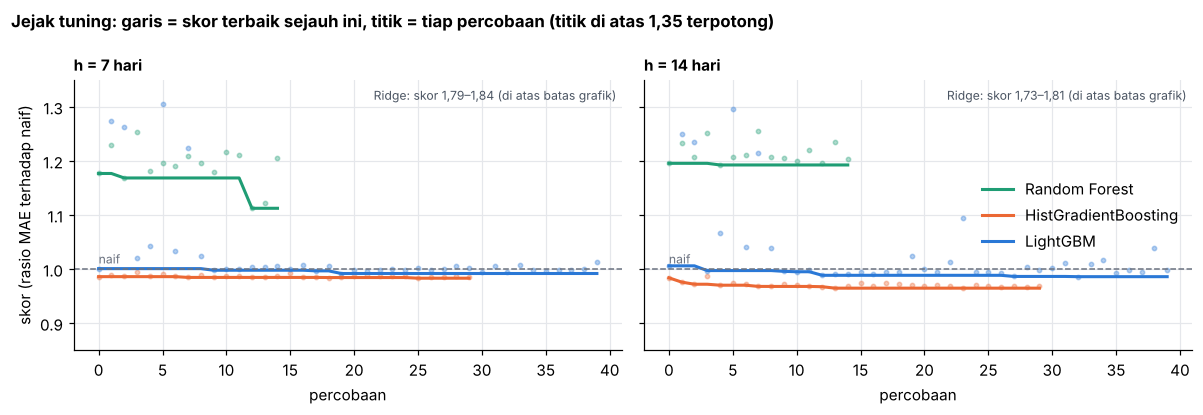

In [21]:
# Jejak tuning: skor terbaik sejauh ini per percobaan
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
WARNA_ALGO = {"ridge": ABU, "random_forest": "#1f9d74", "hist_gb": ORANYE, "lightgbm": BIRU}
for h, ax in zip(HORIZON, axes):
    for a in RUANG:
        d = TUNING[(TUNING.algoritma == a) & (TUNING.h == h)].sort_values("percobaan")
        if a != "ridge":
            ax.plot(d.percobaan, d.skor.cummin(), color=WARNA_ALGO[a], lw=2, label=NAMA_ALGO[a])
        ax.scatter(d.percobaan, d.skor, color=WARNA_ALGO[a], s=8, alpha=0.35)
    ax.axhline(1, color="#6b7280", lw=1, ls="--")
    ax.text(0, 1.005, "naif", fontsize=8, color="#6b7280", va="bottom")
    ax.set_title(f"h = {h} hari", loc="left", fontsize=10, fontweight="bold")
    ax.set_xlabel("percobaan")
    ax.set_ylim(0.85, 1.35)
    r = TUNING[(TUNING.algoritma == "ridge") & (TUNING.h == h)].skor
    ax.text(0.99, 0.97, f"Ridge: skor {r.min():.2f}–{r.max():.2f} (di atas batas grafik)".replace(".", ","),
            transform=ax.transAxes, ha="right", va="top", fontsize=8, color="#4b5563")
axes[0].set_ylabel("skor (rasio MAE terhadap naif)")
axes[1].legend(frameon=False, loc="center right")
fig.suptitle("Jejak tuning: garis = skor terbaik sejauh ini, titik = tiap percobaan (titik di atas 1,35 terpotong)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

### S3.3 Perbandingan algoritma setelah tuning

Setiap algoritma dilatih ulang dengan parameter terbaiknya, lalu dinilai per kelompok di keempat lipatan. Selain rata-rata,
dicatat **berapa lipatan yang lebih baik dari naif** (stabilitas) dan waktu latih satu lipatan terbesar.

In [22]:
OOF, WAKTU = {}, {}
for a in RUANG:
    for h in HORIZON:
        t0 = time.time()
        OOF[(a, h)] = vg.prediksi_lipatan(TAB[h], h, a, TERBAIK.loc[(a, h), "param"], K_FITUR, seed=SEED)
        WAKTU[(a, h)] = (time.time() - t0) / len(vg.LIPATAN)

def tabel_banding(oofs, kolom_pred="pred"):
    baris = []
    for (nama, h), oof in oofs.items():
        r = vg.ringkas(oof, kolom_pred)
        for g, d in r.groupby("kelompok"):
            baris.append({"model": nama, "h": h, "kelompok": g, "vs naif (%)": (d.rasio.mean() - 1) * 100,
                          "lipatan lebih baik dari naif": f"{(d.rasio < 1).sum()}/4",
                          "terburuk (%)": (d.rasio.max() - 1) * 100})
    return pd.DataFrame(baris)

banding = tabel_banding({(NAMA_ALGO[a], h): o for (a, h), o in OOF.items()})
banding = banding.pivot_table(index=["h", "model"], columns="kelompok",
                              values=["vs naif (%)", "lipatan lebih baik dari naif"], aggfunc="first")
banding["waktu latih per lipatan (detik)"] = [WAKTU[({v: k for k, v in NAMA_ALGO.items()}[m], h)] for h, m in banding.index]
print("MAE dibanding naif (%), rata-rata 4 lipatan; negatif = lebih baik")
display(banding.round(1))

MAE dibanding naif (%), rata-rata 4 lipatan; negatif = lebih baik


lipatan lebih baik dari naif        vs naif (%)        waktu latih per lipatan (detik)
kelompok                                  bergejolak stabil  bergejolak stabil                                
h  model                                                                                                      
7  HistGradientBoosting                          3/4    1/4        -3.2   -0.1                             1.2
   LightGBM                                      3/4    1/4        -2.8    1.1                             1.1
   Random Forest                                 3/4    0/4        -2.1   24.5                             3.6
   Ridge                                         3/4    0/4        -1.5  160.4                             0.1
14 HistGradientBoosting                          3/4    1/4        -6.5   -0.6                             0.7
   LightGBM                                      3/4    0/4        -4.9    2.1                             0.5
   Random Forest                                 3/4    0/4        -8.5   47.0                             2.4
   Ridge                                         3/4    0/4        -5.9  152.0                             0.1

### S3.4 Strategi untuk komoditas stabil

Pada komoditas stabil, harga sama persis di 85–97% pasangan hari (S1.4), sehingga setiap "gerak kecil" yang ditebak model
cenderung menambah galat. Tiga strategi diuji pada parameter terbaik tiap algoritma:

| Strategi | Cara |
|---|---|
| **(a) Model per kelompok** | Dua model terpisah: satu untuk komoditas bergejolak, satu untuk stabil (parameter sama) |
| **(b) Penyusutan ke nol** | Prediksi model gabungan disusutkan: $\hat y' = \operatorname{sign}(\hat y)\max(\lvert\hat y\rvert - \tau, 0)$. Ambang $\tau$ dipilih per kelompok dan per horizon dari kisi 0–0,10 (skala log, 0,01 ≈ 1%) |
| **(c) Naif untuk stabil** | Model hanya dipakai untuk bergejolak; komoditas stabil memakai "harga tetap" |

Catatan: ambang $\tau$ dipilih dengan validasi silang yang sama dengan yang dipakai untuk menilainya, sehingga angka (b) sedikit
optimistis. Penilaian yang jujur adalah data uji di S4.

In [23]:
KISI_TAU = [0.0, 0.002, 0.005, 0.01, 0.015, 0.02, 0.03, 0.05, 0.075, 0.1]

def pilih_tau(oof):
    # Ambang terbaik per kelompok: rata-rata rasio MAE terhadap naif atas 4 lipatan paling kecil
    tau = {}
    for g in vg.KELOMPOK:
        d = oof[oof.kelompok == g]
        skor_tau = {t: vg.ringkas(d.assign(p=mg.susut(d.pred.values, t)), "p")["rasio"].mean() for t in KISI_TAU}
        tau[g] = min(skor_tau, key=skor_tau.get)
    return tau

OOF_KEL, TAU, STRATEGI = {}, {}, {}
for a in RUANG:
    for h in HORIZON:
        dasar = OOF[(a, h)]
        OOF_KEL[(a, h)] = vg.prediksi_lipatan(TAB[h], h, a, TERBAIK.loc[(a, h), "param"], K_FITUR, per_kelompok=True, seed=SEED)
        TAU[(a, h)] = pilih_tau(dasar)
        susut_ = dasar.copy()
        for g, t in TAU[(a, h)].items():
            s = susut_.kelompok == g
            susut_.loc[s, "pred"] = mg.susut(susut_.loc[s, "pred"].values, t)
        naif_stabil = dasar.copy()
        naif_stabil.loc[naif_stabil.kelompok == "stabil", "pred"] = 0.0
        for nama, o in [("gabungan", dasar), ("(a) per kelompok", OOF_KEL[(a, h)]), ("(b) penyusutan", susut_),
                        ("(c) naif untuk stabil", naif_stabil)]:
            STRATEGI[(f"{NAMA_ALGO[a]} · {nama}", h)] = o

hasil_strategi = tabel_banding(STRATEGI)
hasil_strategi[["algoritma", "strategi"]] = hasil_strategi.model.str.split(" · ", expand=True)
tabel_strategi = hasil_strategi.pivot_table(index=["h", "algoritma", "strategi"], columns="kelompok",
                                            values=["vs naif (%)", "lipatan lebih baik dari naif"], aggfunc="first")
tabel_strategi[("skor", "rata 2 kelompok")] = tabel_strategi["vs naif (%)"].mean(axis=1)
print("MAE dibanding naif (%), rata-rata 4 lipatan; negatif = lebih baik")
display(tabel_strategi.round(1))
print("Ambang penyusutan terpilih (skala log):")
for (a, h), t in TAU.items():
    print(f"  {NAMA_ALGO[a]:21s} h = {h:2d}: bergejolak {t['bergejolak']}, stabil {t['stabil']}")

MAE dibanding naif (%), rata-rata 4 lipatan; negatif = lebih baik


lipatan lebih baik dari naif        vs naif (%)                   skor
kelompok                                                        bergejolak stabil  bergejolak stabil rata 2 kelompok
h  algoritma            strategi                                                                                    
7  HistGradientBoosting (a) per kelompok                               3/4    1/4        -1.4   -0.0            -0.7
                        (b) penyusutan                                 3/4    1/4        -3.2   -0.1            -1.7
                        (c) naif untuk stabil                          3/4    0/4        -3.2    0.0            -1.6
                        gabungan                                       3/4    1/4        -3.2   -0.1            -1.7
   LightGBM             (a) per kelompok                               3/4    3/4        -3.1   -3.9            -3.5
                        (b) penyusutan                                 3/4    3/4        -2.8   -0.4            -1.6
                        (c) naif untuk stabil                          3/4    0/4        -2.8    0.0            -1.4
                        gabungan                                       3/4    1/4        -2.8    1.1            -0.8
   Random Forest        (a) per kelompok                               3/4    0/4        -2.0   29.0            13.5
                        (b) penyusutan                                 3/4    2/4        -3.2   -0.1            -1.7
                        (c) naif untuk stabil                          3/4    0/4        -2.1    0.0            -1.0
                        gabungan                                       3/4    0/4        -2.1   24.5            11.2
   Ridge                (a) per kelompok                               3/4    0/4        -2.0   62.2            30.1
                        (b) penyusutan                                 3/4    2/4        -2.7    0.1            -1.3
                        (c) naif untuk stabil                          3/4    0/4        -1.5    0.0            -0.7
                        gabungan                                       3/4    0/4        -1.5  160.4            79.5
14 HistGradientBoosting (a) per kelompok                               3/4    1/4        -5.2   -0.5            -2.9
                        (b) penyusutan                                 3/4    1/4        -6.8   -0.6            -3.7
                        (c) naif untuk stabil                          3/4    0/4        -6.5    0.0            -3.2
                        gabungan                                       3/4    1/4        -6.5   -0.6            -3.5
   LightGBM             (a) per kelompok                               3/4    1/4        -6.7    0.1            -3.3
                        (b) penyusutan                                 3/4    0/4        -4.9    0.0            -2.4
                        (c) naif untuk stabil                          3/4    0/4        -4.9    0.0            -2.4
                        gabungan                                       3/4    0/4        -4.9    2.1            -1.4
   Random Forest        (a) per kelompok                               3/4    0/4        -7.3   45.3            19.0
                        (b) penyusutan                                 3/4    3/4        -8.7   -0.5            -4.6
                        (c) naif untuk stabil                          3/4    0/4        -8.5    0.0            -4.3
                        gabungan                                       3/4    0/4        -8.5   47.0            19.3
   Ridge                (a) per kelompok                               3/4    0/4        -6.2   55.4            24.6
                        (b) penyusutan                                 3/4    2/4        -6.3    0.0            -3.1
                        (c) naif untuk stabil                          3/4    0/4        -5.9    0.0            -2.9
                        gabungan                                    

Ambang penyusutan terpilih (skala log):
  Ridge                 h =  7: bergejolak 0.015, stabil 0.1
  Ridge                 h = 14: bergejolak 0.01, stabil 0.1
  Random Forest         h =  7: bergejolak 0.03, stabil 0.05
  Random Forest         h = 14: bergejolak 0.01, stabil 0.075
  HistGradientBoosting  h =  7: bergejolak 0.002, stabil 0.0
  HistGradientBoosting  h = 14: bergejolak 0.01, stabil 0.0
  LightGBM              h =  7: bergejolak 0.002, stabil 0.015
  LightGBM              h = 14: bergejolak 0.0, stabil 0.1


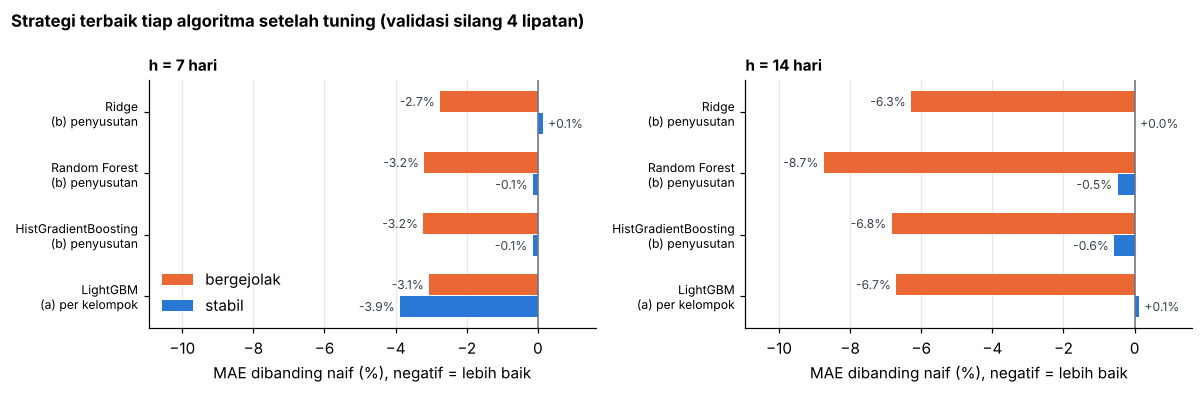

In [24]:
# Ringkasan visual strategi terbaik per algoritma
skor_s = hasil_strategi.groupby(["h", "algoritma", "strategi"])["vs naif (%)"].mean().rename("skor").reset_index()
terbaik_s = skor_s.loc[skor_s.groupby(["h", "algoritma"])["skor"].idxmin()]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for h, ax in zip(HORIZON, axes):
    d = hasil_strategi[hasil_strategi.h == h].merge(terbaik_s[terbaik_s.h == h][["algoritma", "strategi"]])
    urut = [NAMA_ALGO[a] for a in RUANG][::-1]
    yy = {n: i for i, n in enumerate(urut)}
    for g, warna, geser in (("bergejolak", ORANYE, 0.18), ("stabil", BIRU, -0.18)):
        dd = d[d.kelompok == g]
        ax.barh([yy[n] + geser for n in dd.algoritma], dd["vs naif (%)"], height=0.34, color=warna, label=g)
        for n, v in zip(dd.algoritma, dd["vs naif (%)"]):
            ax.text(v + (0.15 if v >= 0 else -0.15), yy[n] + geser, f"{v:+.1f}%", va="center",
                    ha="left" if v >= 0 else "right", fontsize=8, color="#374151")
    ax.set_yticks(range(len(urut)), [f"{n}\n{terbaik_s[(terbaik_s.h == h) & (terbaik_s.algoritma == n)].strategi.iloc[0]}" for n in urut], fontsize=8)
    ax.set_xlim(d["vs naif (%)"].min() - 2.2, max(d["vs naif (%)"].max(), 0) + 1.5)
    ax.axvline(0, color="#6b7280", lw=1)
    ax.set_title(f"h = {h} hari", loc="left", fontsize=10, fontweight="bold")
    ax.set_xlabel("MAE dibanding naif (%), negatif = lebih baik")
    ax.grid(axis="y", visible=False)
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("Strategi terbaik tiap algoritma setelah tuning (validasi silang 4 lipatan)", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

### S3.5 Uji ulang fitur kalender

Seperti dicatat di S2, fitur kalender diuji sekali lagi, kali ini pada kandidat terkuat setelah tuning (LightGBM per kelompok,
lihat S3.6). Parameter tidak diubah; hanya kolom fitur yang ditambah.

In [25]:
ALGO_UJI = "lightgbm"
KAL = [("K (tanpa kalender)", K_FITUR),
       ("K + hari besar", K_FITUR + ["hb_menjelang", "hb_target", "hari_ke_hb"]),
       ("K + Ramadan", K_FITUR + ["ramadan_target"]),
       ("K + bulan", K_FITUR + ["bulan_sin", "bulan_cos"]),
       ("K + semua kalender", K_FITUR + fg.FITUR_GRUP["kalender"])]
OOF_KAL = {(nama, h): vg.prediksi_lipatan(TAB[h], h, ALGO_UJI, TERBAIK.loc[(ALGO_UJI, h), "param"], kolom, per_kelompok=True, seed=SEED)
           for nama, kolom in KAL for h in HORIZON}
tabel_kal = tabel_banding(OOF_KAL).pivot_table(index=["h", "model"], columns="kelompok",
                                               values=["vs naif (%)", "lipatan lebih baik dari naif"], aggfunc="first")
tabel_kal[("skor", "rata 2 kelompok")] = tabel_kal["vs naif (%)"].mean(axis=1)
tabel_kal = tabel_kal.reindex([(h, n) for h in HORIZON for n, _ in KAL])
print("LightGBM per kelompok: MAE dibanding naif (%), rata-rata 4 lipatan")
display(tabel_kal.round(1))

LightGBM per kelompok: MAE dibanding naif (%), rata-rata 4 lipatan


lipatan lebih baik dari naif        vs naif (%)                   skor
kelompok                                bergejolak stabil  bergejolak stabil rata 2 kelompok
h  model                                                                                    
7  K (tanpa kalender)                          3/4    3/4        -3.1   -3.9            -3.5
   K + hari besar                              2/4    3/4         0.7   -3.5            -1.4
   K + Ramadan                                 3/4    3/4        -1.4   -2.9            -2.2
   K + bulan                                   3/4    3/4         3.3   -4.2            -0.4
   K + semua kalender                          2/4    3/4         3.4   -2.5             0.4
14 K (tanpa kalender)                          3/4    1/4        -6.7    0.1            -3.3
   K + hari besar                              3/4    1/4        -2.6    0.1            -1.2
   K + Ramadan                                 3/4    1/4        -6.9    0.0            -3.4
   K + bulan                                   3/4    1/4        -2.9   -0.1            -1.5
   K + semua kalender                          3/4    0/4        -0.8    0.1            -0.4

Hasilnya sama dengan S2: fitur kalender **tidak** menurunkan galat. Pada h = 7 setiap tambahan kalender membuat komoditas bergejolak
lebih buruk (misalnya +0,7% dengan hari besar dan +3,3% dengan bulan, dibanding −3,1% tanpa kalender). Pada h = 14 hanya Ramadan yang
hampir sama (−3,4% dibanding −3,3%), selisih yang terlalu kecil untuk membenarkan fitur tambahan. Kalender tetap tidak dipakai.

### S3.6 Pemilihan model

Kandidat dibandingkan pada kedua horizon sekaligus, karena aplikasi lebih sederhana dan lebih mudah dijelaskan bila memakai
satu jenis model untuk h = 7 dan h = 14.

In [26]:
KANDIDAT = [("lightgbm", "(a) per kelompok"), ("random_forest", "(b) penyusutan"), ("hist_gb", "(b) penyusutan"),
            ("hist_gb", "gabungan"), ("lightgbm", "gabungan"), ("ridge", "(b) penyusutan")]
baris = []
for a, strat in KANDIDAT:
    r = {"algoritma": NAMA_ALGO[a], "strategi": strat}
    for h in HORIZON:
        d = vg.ringkas(STRATEGI[(f"{NAMA_ALGO[a]} · {strat}", h)])
        per_g = d.groupby("kelompok").rasio.mean()
        r[f"h{h} bergejolak (%)"] = (per_g["bergejolak"] - 1) * 100
        r[f"h{h} stabil (%)"] = (per_g["stabil"] - 1) * 100
        r[f"h{h} skor (%)"] = (d.rasio.mean() - 1) * 100
    r["rata 2 horizon (%)"] = np.mean([r[f"h{h} skor (%)"] for h in HORIZON])
    r["ambang dipilih di CV (optimistis)"] = "ya" if "penyusutan" in strat else "tidak"
    r["waktu latih per lipatan (detik)"] = np.mean([WAKTU[(a, h)] for h in HORIZON]) * (2 if "per kelompok" in strat else 1)
    baris.append(r)
pilihan = pd.DataFrame(baris).sort_values("rata 2 horizon (%)").set_index(["algoritma", "strategi"])
print("MAE dibanding naif (%), rata-rata 4 lipatan; negatif = lebih baik")
display(pilihan.round(1))

# Konfigurasi terpilih: dipakai S4 (evaluasi di data uji) dan S6 (aplikasi)
TERPILIH = {
    "algoritma": "lightgbm", "strategi": "per_kelompok", "fitur": K_FITUR, "seed": SEED,
    "kelompok_bergejolak": list(fg.BERGEJOLAK),
    "param": {str(h): TERBAIK.loc[("lightgbm", h), "param"] for h in HORIZON},
    "data_sampai": str(BATAS_DATA.date()), "dipilih_di": "notebooks/pemodelan.ipynb S3.6 (validasi silang 4 lipatan)",
}
(ROOT / "docs" / "model" / "s3_terpilih.json").write_text(json.dumps(TERPILIH, indent=2, ensure_ascii=False), encoding="utf-8")
print("Tersimpan: docs/model/s3_terpilih.json")

MAE dibanding naif (%), rata-rata 4 lipatan; negatif = lebih baik


h7 bergejolak (%)  h7 stabil (%)  h7 skor (%)  h14 bergejolak (%)  h14 stabil (%)  h14 skor (%)  rata 2 horizon (%)  \
algoritma            strategi                                                                                                                                
LightGBM             (a) per kelompok               -3.1           -3.9         -3.5                -6.7             0.1          -3.3                -3.4   
Random Forest        (b) penyusutan                 -3.2           -0.1         -1.7                -8.7            -0.5          -4.6                -3.1   
HistGradientBoosting (b) penyusutan                 -3.2           -0.1         -1.7                -6.8            -0.6          -3.7                -2.7   
                     gabungan                       -3.2           -0.1         -1.7                -6.5            -0.6          -3.5                -2.6   
Ridge                (b) penyusutan                 -2.7            0.1         -1.3                -6.3             0.0          -3.1                -2.2   
LightGBM             gabungan                       -2.8            1.1         -0.8                -4.9             2.1          -1.4                -1.1   

                                      ambang dipilih di CV (optimistis)  waktu latih per lipatan (detik)  
algoritma            strategi                                                                             
LightGBM             (a) per kelompok                             tidak                              1.7  
Random Forest        (b) penyusutan                                  ya                              3.0  
HistGradientBoosting (b) penyusutan                                  ya                              1.0  
                     gabungan                                     tidak                              1.0  
Ridge                (b) penyusutan                                  ya                              0.1  
LightGBM             gabungan                                     tidak                              0.8

Tersimpan: docs/model/s3_terpilih.json


**Model terpilih: LightGBM, satu model untuk komoditas bergejolak dan satu untuk komoditas stabil, per horizon (4 model).**

Alasan:
1. **Skor terbaik rata-rata kedua horizon** (−3,4%), dan satu-satunya kandidat yang **lebih baik dari naif di kedua kelompok pada
   h = 7**: bergejolak −3,1%, stabil −3,9%. Untuk komoditas stabil, model ini lebih baik dari naif di 3 dari 4 lipatan, sedangkan
   rata-rata stabil kandidat lain hanya sekitar naif (−0,4% sampai +0,1%).
2. **Tidak memakai ambang yang dipilih di validasi silang.** Kandidat penyusutan (Random Forest −3,1%, HistGradientBoosting −2,7%)
   bergantung pada ambang τ yang dipilih dan dinilai di lipatan yang sama, sehingga angkanya optimistis. Skor LightGBM per kelompok
   tidak punya sumber optimisme itu.
3. **Cepat dan ringan:** sekitar 2 detik per lipatan untuk dua model, dibanding Random Forest yang lebih lambat dan berukuran besar.
   Ini penting karena aplikasi melatih ulang model setiap kali data berubah (S6).
4. Random Forest penyusutan memang terbaik pada h = 14 (−4,6% dibanding −3,3%), tetapi pada h = 7 jauh lebih lemah (−1,7% dibanding
   −3,5%), dan stabilnya bergantung penuh pada ambang penyusutan yang besar (0,075).

**Posisi terhadap kriteria sukses S1** (sementara, dari validasi silang; angka resmi dari data uji di S4):

| Kelompok | Kriteria minimum | LightGBM per kelompok (CV) |
|---|---|---|
| Bergejolak h = 7 | MAE lebih kecil dari naif | −3,1%: **terpenuhi** (target −5% belum) |
| Bergejolak h = 14 | MAE lebih kecil dari naif | −6,7%: **terpenuhi**, juga target ≥ 5% |
| Stabil h = 7 | tidak lebih dari 5% lebih buruk dari naif | −3,9%: **terpenuhi**, lebih baik dari naif |
| Stabil h = 14 | tidak lebih dari 5% lebih buruk dari naif | +0,1%: **terpenuhi** |

**Yang dibawa ke S4–S5:**
- S4 melatih model terpilih dengan seluruh data latih dan validasi (hari target sampai 30 Juni 2026), lalu menilainya **sekali** di
  data uji, dibanding naif dan model lama, termasuk status Normal / Waspada / Lonjakan.
- Lipatan 1 (Jul–Sep 2025) tetap lebih buruk dari naif untuk komoditas bergejolak di semua algoritma; dianalisis di S5.